<img src="../../images/ost_logo.png" width="240" align="right"/>
<div style="text-align: left"> <b> Bachelorarbeit </b> <br> FS 2026 <br> <a href="mailto:ryan.mikus@ost.ch"> Ryan Mikus </a> und <a href="mailto:ilija.amato@ost.ch"> Ilija Amato </a> </div>

---

# 04 — Übersicht: Beste Hyperparameter aus 03 (alle Baskets/Kerzenlängen)

Liest **alle** gespeicherten Tuning-Läufe aus `03_tune_dynamic_vol.ipynb`
(`src.backtest.tuning.load_all_tuning_results`, egal ob automatische Alle-Baskets-Suche,
manuelles Widget-Panel, oder der Alle-Kerzenlängen-Auto-Modus) und baut daraus für jede
Basket×Kerzenlänge-Kombination einen **vollständigen, ausführlichen** Backtest mit
Kennzahlen, Trade-Analyse und mehreren Vergleichsgrafiken.

**Test vs. Validierung, ohne Data-Snooping:** Die Parameter in `08` wurden ausschliesslich
auf `CALIBRATION_RANGE` (älteste 80 % des verfügbaren Zeitraums) gesucht — `BACKTEST_RANGE`
(neueste 20 %) wurde dabei **nie** angefasst (`src.backtest.config.split_calibration_backtest`).
Dieses Notebook führt pro Kombination **einen** Backtest über den **gesamten** verfügbaren
Zeitraum aus und teilt danach Trades/Equity-Kurve in genau diese zwei Fenster:

- **Test** (`CALIBRATION_RANGE`) — in-sample bezüglich der Parameterwahl, zeigt wie gut die
  gefundenen Parameter zur Kalibrierungsperiode selbst passen.
- **Validierung** (`BACKTEST_RANGE`) — echtes Out-of-Sample, die Parameter haben diese Daten
  beim Tuning nie gesehen. Der Vergleich Test vs. Validierung ist der zentrale
  Overfitting-Check dieses Notebooks: bricht die Performance in der Validierung stark ein,
  sind die gefundenen Parameter vermutlich auf die Kalibrierungsperiode überangepasst.

Jede Kombination wird zusätzlich als eigenständiger Run über `src.backtest.runs.save_run`
gespeichert (Label-Suffix `-test`/`-validation`), damit sie auch in
`02_run_comparison.ipynb` auftaucht.

Zusätzlich zum reinen Netto-Lauf (mit den echten Fee-/Slippage-Annahmen aus `BASE_PARAMS`)
rechnet dieses Notebook **zwei Kostenszenarien** zum Vergleich mit: komplett kostenfrei
(`fee_bps=0`, `slippage=0`) und eine reduzierte, feste Gebühr (`fee_bps=2`, ohne Slippage) --
zeigt, wie viel der Netto-Performance durch Handelskosten/Slippage aufgezehrt wird. Alle drei
Szenarien laufen durch **dieselben** Helper-Funktionen (Abschnitt 5), nur mit unterschiedlichen
Kosten-Overrides und eigenen Cache-Unterordnern.

**Nicht direkt ausführen ohne mindestens einen gespeicherten Lauf aus `08`.** Ohne
gespeicherte Tuning-Ergebnisse unter `data/processed/tuning/` bricht Abschnitt 2 mit einer
klaren Fehlermeldung ab.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path("../..").resolve()))

import warnings
warnings.filterwarnings("ignore")

from dataclasses import replace as _dc_replace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

from src.data import load_ohlcv_panel, load_symbol_map
from src.backtest.cliques import CliqueTimeline
from src.backtest.config import BacktestConfig, BasketParams, split_calibration_backtest, DateRange, scale_candle_fields_to_candle_minutes
from src.backtest.engine import BacktestEngine
from src.backtest import metrics as bt_metrics
from src.backtest import plots as bt_plots
from src.backtest import runs as bt_runs
from src.backtest import tuning as bt_tuning

print("Imports OK")

Imports OK


## 1. Run-Konfiguration

Muss zum Tuning-Lauf aus `03_tune_dynamic_vol.ipynb` passen, den dieses Notebook auswertet
(gleiches `DATA_START`/`DATA_END`/`BACKTEST_FRACTION`/`CLIQUE_VARIANT`/`STRATEGY_NAME`,
sonst ist `CALIBRATION_RANGE`/`BACKTEST_RANGE` nicht deckungsgleich mit dem, worauf die
gespeicherten `best_params` tatsächlich gesucht wurden).

In [2]:
RUN_LABEL_PREFIX = "tuning_overview"  # Praefix fuer die hier gespeicherten Runs

# Einzige verbliebene Tuning-Quelle: data/processed/tuning_dbstore_final/ -- die aus
# optuna_walkforward.db (Studien-Suffix -5db5a7ab) extrahierten best_params.json. Der
# fruehere "default"-Ordner (data/processed/tuning/, bt_tuning.TUNING_DIR) existiert nicht
# mehr, der TUNING_SOURCE-Umschalter entfaellt deshalb. Achtung: tuning_dbstore_final
# deckt Basket 1 bei 15/30/60/240min NICHT ab (dort in der DB nur PRUNED-Trials, kein
# gueltiges Ergebnis).
TUNING_DIR_ACTIVE = bt_tuning.TUNING_DIR.parent / "tuning_dbstore_final"

DATA_START = pd.Timestamp("2024-07-23", tz="UTC")   # muss zu 03_tune_dynamic_vol.ipynb passen
DATA_END = pd.Timestamp("2026-07-22", tz="UTC")
BACKTEST_FRACTION = 0.2  # identisch zu 03_tune_dynamic_vol.ipynb -- neueste 20% = Validierung

# NEU: fuer einen schnellen Funktionstest dieses Notebooks (nicht fuer echte Auswertung!)
# -- kuerzt Test- UND Validierungsfenster nach dem Split (Abschnitt 4) je auf 1/3 ihrer
# urspruenglichen Laenge, OHNE das 80/20-Verhaeltnis (BACKTEST_FRACTION) selbst zu aendern.
# Test wird dabei auf sein LETZTES Drittel gekuerzt, Validierung auf ihr ERSTES Drittel --
# beide bleiben direkt aneinander angrenzend, nur insgesamt weniger Bars zu simulieren
# (schnellere Panel-/Engine-Laufzeit). Fuer die Thesis QUICK_TEST=False lassen.
QUICK_TEST = True
QUICK_TEST_FRACTION = 1 / 3

# Basket 4 wie in 03_tune_dynamic_vol.ipynb ausgeschlossen (siehe dortige Begruendung:
# zu wenige Clique-Snapshots im gesamten Backtest-Zeitraum).
BASKETS = ("Basket 1", "Basket 2", "Basket 3")
CLIQUE_VARIANT = "raw_24h"
STRATEGY_NAME = "pairwise_zscore"
INITIAL_CAPITAL = 100_000.0

# BASE_PARAMS nur als Ausgangspunkt fuer Felder, die NICHT in den gespeicherten
# best_params stehen (z.B. wenn ein Tuning-Lauf nur einen Teil der Parameter gesucht hat) --
# symmetric_exit/dynamic_threshold_enabled/dynamic_sizing_enabled bleiben wie in 08 fest an.
# Angeglichen an die FIX-Werte ("tunen"=AUS) aus dem Widget-Panel in
# 03_tune_dynamic_vol.ipynb zum Zeitpunkt der tuning_dbstore_final-Laeufe -- diese
# Laeufe wurden VOR der fixed_overrides-Speicherung erzeugt (siehe save_tuning_results
# in src/backtest/tuning.py) und tragen deshalb selbst KEINE Fix-Werte im gespeicherten
# best_params.json. Ohne diesen Abgleich wuerde der finale Backtest hier mit ANDEREN
# Fix-Werten laufen als das damalige Tuning (v.a. formation_window_candles war 7 statt
# 20 Tage, vol_regime_percentile_window_candles 60 statt 35 Tage) -- fuer NEUE Laeufe
# (die fixed_overrides im JSON mitbringen) ist dieser BASE_PARAMS-Wert ohnehin nur
# Fallback (siehe Abschnitt 5, Schicht 1 von 3: BASE_PARAMS < fixed_overrides <
# best_params), die Werte hier sollten also die aktuellen Panel-Fix-Werte spiegeln.
BASE_PARAMS = BasketParams(
    entry_z=2.0, exit_z=0.5, stop_z=5.0,
    max_holding_days=4.0,
    sizing_multiplier_cap=4.0,
    formation_window_candles=288 * 20,
    max_candidate_pairs=3, pair_prefilter_top_n=15,
    min_half_life_candles=6, max_half_life_candles=288 * 2,
    max_concurrent_positions=3,
    fee_bps=10.0, slippage_bps=2.0,
    symmetric_exit=True, dynamic_threshold_enabled=True, dynamic_sizing_enabled=True,
    vol_regime_lookback_candles=288, vol_regime_percentile_window_candles=35 * 288,
    vol_regime_low_percentile=20.0, vol_regime_high_percentile=80.0,
)

# Kostenszenarien, die neben dem Netto-Lauf (BASE_PARAMS-Kosten) mitgerechnet werden
# (Abschnitt 5b) -- (Anzeigename, Overrides, Cache-Suffix).
COST_SCENARIOS = [
    ("kostenfrei", {"fee_bps": 0.0, "slippage_bps": 0.0, "slippage_high_low_factor": 0.0}, "zero_cost"),
    ("fee_bps=2, ohne Slippage", {"fee_bps": 2.0, "slippage_bps": 0.0, "slippage_high_low_factor": 0.0}, "fee2bps_noslip"),
]

## 2. Tuning-Ergebnisse laden & beste Parameter je Basket/Kerzenlänge auswählen

In [3]:
all_tuning_df = bt_tuning.load_all_tuning_results(TUNING_DIR_ACTIVE)
if all_tuning_df.empty:
    raise SystemExit(
        f"Keine gespeicherten Tuning-Laeufe unter {TUNING_DIR_ACTIVE} gefunden -- "
        "zuerst 03_tune_dynamic_vol.ipynb ausfuehren und mindestens einen Lauf nach "
        "data/processed/tuning_dbstore_final/ speichern."
    )

print(f"{len(all_tuning_df)} gespeicherte Basket-Eintraege ueber {all_tuning_df['run_id'].nunique()} Laeufe gefunden.")
display(all_tuning_df.sort_values(["basket", "candle_minutes", "best_objective"], ascending=[True, True, False]))

# Pro (basket, candle_minutes) NUR den Eintrag mit dem hoechsten best_objective behalten --
# koennen mehrere sein, falls z.B. mehrfach mit derselben Kerzenlaenge getunt wurde.
BEST_PER_BASKET_CANDLE = (
    all_tuning_df.dropna(subset=["candle_minutes"])
    .sort_values("best_objective", ascending=False)
    .drop_duplicates(subset=["basket", "candle_minutes"])
    .sort_values(["basket", "candle_minutes"])
    .reset_index(drop=True)
)
print(f"\n{len(BEST_PER_BASKET_CANDLE)} eindeutige Basket x Kerzenlaenge-Kombinationen:")
display(BEST_PER_BASKET_CANDLE[["run_id", "basket", "candle_minutes", "fee_preset", "best_objective", "n_trials", "n_folds"]])

14 gespeicherte Basket-Eintraege ueber 14 Laeufe gefunden.


,run_id,basket,candle_minutes,fee_preset,best_objective,n_trials,n_folds,best_params,fixed_overrides
1,basket-1-5min-standard-5db5a7ab,Basket 1,5,standard,-0.042991,20,None,"{'entry_z': 0.9883533267314155, 'entry_z_delta...",{}
0,basket-1-10min-standard-5db5a7ab,Basket 1,10,standard,-0.045733,20,None,"{'entry_z': 0.37616262889446905, 'entry_z_delt...",{}
6,basket-2-5min-standard-5db5a7ab,Basket 2,5,standard,-0.037372,20,None,"{'entry_z': 2.388169046927335, 'entry_z_delta'...",{}
2,basket-2-10min-standard-5db5a7ab,Basket 2,10,standard,-0.039099,20,None,"{'entry_z': 1.298141623154969, 'entry_z_delta'...",{}
3,basket-2-15min-standard-5db5a7ab,Basket 2,15,standard,-0.025066,20,None,"{'entry_z': 1.2728931157247838, 'entry_z_delta...",{}
5,basket-2-30min-standard-5db5a7ab,Basket 2,30,standard,-0.034447,20,None,"{'entry_z': 0.8771797252439497, 'entry_z_delta...",{}
7,basket-2-60min-standard-5db5a7ab,Basket 2,60,standard,-0.043103,20,None,"{'entry_z': 0.37616262889446905, 'entry_z_delt...",{}
4,basket-2-240min-standard-5db5a7ab,Basket 2,240,standard,-0.055431,20,None,"{'entry_z': 0.4116980943737963, 'entry_z_delta...",{}
12,basket-3-5min-standard-5db5a7ab,Basket 3,5,standard,-0.053239,20,None,"{'entry_z': 2.233216666807617, 'entry_z_delta'...",{}
8,basket-3-10min-standard-5db5a7ab,Basket 3,10,standard,-0.040882,20,None,"{'entry_z': 1.6857984397352412, 'entry_z_delta...",{}



14 eindeutige Basket x Kerzenlaenge-Kombinationen:


,run_id,basket,candle_minutes,fee_preset,best_objective,n_trials,n_folds
0,basket-1-5min-standard-5db5a7ab,Basket 1,5,standard,-0.042991,20,None
1,basket-1-10min-standard-5db5a7ab,Basket 1,10,standard,-0.045733,20,None
2,basket-2-5min-standard-5db5a7ab,Basket 2,5,standard,-0.037372,20,None
3,basket-2-10min-standard-5db5a7ab,Basket 2,10,standard,-0.039099,20,None
4,basket-2-15min-standard-5db5a7ab,Basket 2,15,standard,-0.025066,20,None
5,basket-2-30min-standard-5db5a7ab,Basket 2,30,standard,-0.034447,20,None
6,basket-2-60min-standard-5db5a7ab,Basket 2,60,standard,-0.043103,20,None
7,basket-2-240min-standard-5db5a7ab,Basket 2,240,standard,-0.055431,20,None
8,basket-3-5min-standard-5db5a7ab,Basket 3,5,standard,-0.053239,20,None
9,basket-3-10min-standard-5db5a7ab,Basket 3,10,standard,-0.040882,20,None


## 3. Daten laden

`PANEL_5M` einmal im 5-Min-Basisraster geladen, jede andere Kerzenlänge wird daraus per
`src.data.resample_ohlcv_panel` abgeleitet und gecacht -- analog zu `03_tune_dynamic_vol.ipynb`.

In [4]:
from src.data import resample_ohlcv_panel

id_to_symbol, symbol_to_id = load_symbol_map()

PANEL_5M = load_ohlcv_panel(start=DATA_START, end=DATA_END, fields=("open", "high", "low", "close"))
print(f"Panel (5min-Basis): {PANEL_5M['close'].shape[0]:,} Kerzen x {PANEL_5M['close'].shape[1]} Symbole")

timeline = CliqueTimeline.from_cache(
    variant=CLIQUE_VARIANT, id_to_symbol=id_to_symbol, baskets=list(BASKETS),
    start=DATA_START, end=DATA_END,
)
print(timeline.describe())

_panel_cache: dict[int, dict] = {5: PANEL_5M}


def get_panel_for_candle_minutes(candle_minutes: int) -> dict:
    if candle_minutes not in _panel_cache:
        _panel_cache[candle_minutes] = resample_ohlcv_panel(PANEL_5M, source_minutes=5, target_minutes=candle_minutes)
    return _panel_cache[candle_minutes]

Panel (5min-Basis): 209,953 Kerzen x 47 Symbole
Discovery-Intervall (Median über Baskets): 1 days 00:00:00
  Basket 1: 531 Snapshots, 2024-07-29 00:00:00+00:00 → 2026-07-22 00:00:00+00:00, Intervall 1 days 00:00:00
  Basket 2: 605 Snapshots, 2024-07-29 00:00:00+00:00 → 2026-07-22 00:00:00+00:00, Intervall 1 days 00:00:00
  Basket 3: 459 Snapshots, 2024-08-05 00:00:00+00:00 → 2026-06-24 00:00:00+00:00, Intervall 1 days 00:00:00


## 4. Calibration/Backtest-Split (Test vs. Validierung)

Identisch zum Split, auf dem `03_tune_dynamic_vol.ipynb` die Parameter gesucht hat --
`CALIBRATION_RANGE` = Test-Fenster (in-sample bzgl. Parameterwahl), `BACKTEST_RANGE` =
Validierungs-Fenster (echtes Out-of-Sample, neueste 20 %).

In [9]:
CALIBRATION_RANGE, BACKTEST_RANGE = split_calibration_backtest(DATA_START, DATA_END, fraction=BACKTEST_FRACTION)
assert CALIBRATION_RANGE.end < BACKTEST_RANGE.start

if QUICK_TEST:
    # Test (CALIBRATION_RANGE) auf ihr LETZTES Drittel kuerzen (naeher an BACKTEST_RANGE),
    # Validierung (BACKTEST_RANGE) auf ihr ERSTES Drittel kuerzen (naeher an CALIBRATION_RANGE)
    # -- beide bleiben direkt aneinander angrenzend, das 80/20-Gesamtverhaeltnis bleibt
    # unveraendert, nur die absolute Laenge (und damit die zu simulierenden Bars) sinkt.
    cal_days = (CALIBRATION_RANGE.end - CALIBRATION_RANGE.start).days + 1
    cal_third_days = max(1, round(cal_days))
    CALIBRATION_RANGE = DateRange(CALIBRATION_RANGE.end - pd.Timedelta(days=cal_third_days - 1), CALIBRATION_RANGE.end)

    bt_days = (BACKTEST_RANGE.end - BACKTEST_RANGE.start).days + 1
    bt_third_days = max(1, round(bt_days))
    BACKTEST_RANGE = DateRange(BACKTEST_RANGE.start, BACKTEST_RANGE.start + pd.Timedelta(days=bt_third_days - 1))

    print(f"QUICK_TEST aktiv -- Test/Validierung je auf {QUICK_TEST_FRACTION:.0%} ihrer urspruenglichen Laenge gekuerzt (nur fuer Funktionstest, nicht fuer die Thesis-Auswertung).\n")

assert CALIBRATION_RANGE.end < BACKTEST_RANGE.start
print(f"Test (= CALIBRATION_RANGE, in-sample):        {CALIBRATION_RANGE.start.date()} -> {CALIBRATION_RANGE.end.date()}")
print(f"Validierung (= BACKTEST_RANGE, out-of-sample): {BACKTEST_RANGE.start.date()} -> {BACKTEST_RANGE.end.date()}")

QUICK_TEST aktiv -- Test/Validierung je auf 33% ihrer urspruenglichen Laenge gekuerzt (nur fuer Funktionstest, nicht fuer die Thesis-Auswertung).

Test (= CALIBRATION_RANGE, in-sample):        2024-07-23 -> 2026-02-26
Validierung (= BACKTEST_RANGE, out-of-sample): 2026-02-27 -> 2026-07-22


## 5. Backtest-Kern: Slice-Helper & Kostenszenario-Runner

Gemeinsame Helper für **alle** Backtest-Läufe dieses Notebooks (Netto + beide
Kostenszenarien aus Abschnitt 1): pro Basket×Kerzenlänge-Kombination **ein** Engine-Lauf über
den gesamten Zeitraum, danach wird in Test/Validierung gesliced (`_slice_result`) -- ein
gemeinsamer Lauf über den vollen Zeitraum ist identisch zu zwei getrennten Läufen (keine
Re-Kalibrierung an der Nahtstelle, siehe G4 Look-Ahead-Guard), aber nur halb so teuer.

`run_cost_scenario(cost_overrides, cache_suffix, ...)` kapselt die komplette Schleife
(Parameter-Merge, Warm-up-Guard, Disk-Cache, Engine-Lauf, Slicing, `bt_runs.save_run`) --
für den Netto-Lauf mit `cost_overrides={}` aufgerufen, für die Vergleichsläufe aus
`COST_SCENARIOS` mit den jeweiligen Fee-/Slippage-Overrides. Vorher dreimal fast identischer
Copy-Paste-Code (Netto/kostenfrei/fee_bps=2), jetzt eine einzige Funktion.

In [10]:
def _slice_result(full_result, *, config, date_range: DateRange, benchmark_close):
    '''Baut aus einem vollen BacktestResult ein Teil-Ergebnis fuer NUR date_range --
    Trades nach entry_timestamp gefiltert, Equity-Kurve auf den Zeitraum zugeschnitten
    (auf den Equity-Stand am Fensterbeginn normiert, damit total_return NICHT die
    Performance des jeweils anderen Fensters mitschleppt). config bekommt ein eigenes
    backtest_range=date_range, damit compute_all_metrics/metrics_by_basket exakt auf
    diesem Ausschnitt rechnen.'''
    from src.backtest.types import BacktestResult

    window_kind = "test" if date_range == CALIBRATION_RANGE else "validation"
    sub_config = _dc_replace(
        config, backtest_range=date_range, calibration_range=None,
        label=f"{config.label}-{window_kind}",
    )

    trades = full_result.trades
    if not trades.empty:
        mask = (trades["entry_timestamp"] >= date_range.start) & (trades["entry_timestamp"] <= date_range.end)
        sub_trades = trades[mask].reset_index(drop=True)
    else:
        sub_trades = trades

    equity = full_result.equity_curve
    if not equity.empty:
        sub_equity = equity.loc[date_range.start:date_range.end].copy()
        if not sub_equity.empty and "equity" in sub_equity:
            sub_equity["equity"] = sub_equity["equity"] / sub_equity["equity"].iloc[0] * config.initial_capital
    else:
        sub_equity = equity

    sub_metrics = bt_metrics.compute_all_metrics(
        equity_curve=sub_equity, trades=sub_trades, benchmark_close=benchmark_close, config=sub_config,
    )
    sub_metrics_by_basket = bt_metrics.metrics_by_basket(sub_trades, sub_config)

    return BacktestResult(
        run_id=None, config=sub_config, equity_curve=sub_equity, trades=sub_trades,
        metrics=sub_metrics, metrics_by_basket=sub_metrics_by_basket,
        positions_curve=None, meta=dict(full_result.meta),
    )


import pickle


def _cache_path(cache_dir: Path, basket: str, candle_minutes: int) -> Path:
    slug = basket.replace(" ", "-")
    return cache_dir / f"{slug}_{candle_minutes}min.pkl"


def _load_cached_full_result(*, cache_dir: Path, basket: str, candle_minutes: int, best_params: dict, full_range: DateRange, force_recompute: bool):
    '''Laedt den Cache-Eintrag fuer (basket, candle_minutes) NUR, wenn die darin
    hinterlegten best_params/full_range exakt zu den aktuell aus 03 geladenen besten
    Parametern passen -- best_params-Vergleich ueber sorted(items()), da dict-Reihenfolge
    zwischen JSON-Ladevorgaengen nicht garantiert identisch ist.'''
    cache_path = _cache_path(cache_dir, basket, candle_minutes)
    if force_recompute or not cache_path.exists():
        return None
    try:
        with open(cache_path, "rb") as f:
            payload = pickle.load(f)
    except Exception as exc:  # noqa: BLE001 -- ein kaputter/inkompatibler Cache-Eintrag
        # (z.B. nach einer Aenderung an BacktestResult/BacktestConfig) darf den Lauf
        # nicht abbrechen, einfach neu rechnen statt zu crashen.
        print(f"  Cache-Eintrag {cache_path.name} konnte nicht geladen werden ({exc}) -- rechne neu.")
        return None

    cached_params_match = sorted(payload["best_params"].items()) == sorted(best_params.items())
    cached_range_match = (
        payload["full_range"].start == full_range.start and payload["full_range"].end == full_range.end
    )
    if not cached_params_match:
        print(f"  Cache {cache_path.name}: best_params haben sich geaendert (08 hat vermutlich neu/besser "
              f"getunt) -- verworfen, rechne neu.")
        return None
    if not cached_range_match:
        print(f"  Cache {cache_path.name}: simulierter Zeitraum hat sich geaendert (z.B. QUICK_TEST) -- "
              f"verworfen, rechne neu.")
        return None
    return payload["full_result"]


def _save_cached_full_result(*, cache_dir: Path, basket: str, candle_minutes: int, best_params: dict, full_range: DateRange, full_result) -> None:
    payload = {"best_params": dict(best_params), "full_range": full_range, "full_result": full_result}
    with open(_cache_path(cache_dir, basket, candle_minutes), "wb") as f:
        pickle.dump(payload, f)


FORCE_RECOMPUTE = False  # True = alle Caches ignorieren und ALLE Kombinationen/Szenarien neu rechnen


def run_cost_scenario(*, cost_overrides: dict, cache_suffix: str, label_suffix: str = "",
                       allowed_keys: set | None = None, verbose_debug: bool = False):
    '''Fuehrt die komplette Basket x Kerzenlaenge-Schleife (aus BEST_PER_BASKET_CANDLE)
    einmal durch, mit cost_overrides zusaetzlich ueber die (fixed_overrides < best_params)
    Parameter-Schichten gelegt (siehe Kommentar unten). cache_suffix waehlt einen eigenen
    Cache-Unterordner unter TUNING_DIR_ACTIVE/_cache_09_dbstore_final[_{cache_suffix}],
    damit sich die Szenarien nie gegenseitig ueberschreiben. allowed_keys beschraenkt die
    Schleife optional auf bereits im Netto-Lauf erfolgreiche Kombinationen (Kostenszenarien
    sollen nicht mehr Kombinationen liefern als der Netto-Lauf, siehe Abschnitt 5b).

    Gibt (full_results, test_results, validation_results, test_run_ids, validation_run_ids,
    skipped) zurueck -- exakt dieselbe Struktur wie vorher lose Modul-Variablen
    FULL_RESULTS/TEST_RESULTS/... pro Szenario.'''
    cache_dir_name = "_cache_09_dbstore_final" + (f"_{cache_suffix}" if cache_suffix else "")
    cache_dir = TUNING_DIR_ACTIVE / cache_dir_name
    cache_dir.mkdir(parents=True, exist_ok=True)

    full_results: dict[tuple[str, int], object] = {}
    test_results: dict[tuple[str, int], object] = {}
    validation_results: dict[tuple[str, int], object] = {}
    test_run_ids: list[str] = []
    validation_run_ids: list[str] = []
    skipped: list[dict] = []

    for _, row in BEST_PER_BASKET_CANDLE.iterrows():
        basket, candle_minutes, best_params = row["basket"], int(row["candle_minutes"]), row["best_params"]
        fixed_overrides = row.get("fixed_overrides") or {}
        key = (basket, candle_minutes)
        if allowed_keys is not None and key not in allowed_keys:
            continue  # Kombination wurde im Netto-Lauf bereits als SKIPPED protokolliert

        scenario_tag = f" -- {label_suffix}" if label_suffix else ""
        print(f"\n{'=' * 70}\n{basket} @ {candle_minutes}min{scenario_tag} (run_id={row['run_id']})\n{'=' * 70}")

        panel = get_panel_for_candle_minutes(candle_minutes)

        # Parameter-Aufbau in DREI Schichten, aufsteigende Prioritaet:
        #   1) BASE_PARAMS (dieses Notebook, skaliert auf candle_minutes) -- NUR Fallback
        #      fuer Felder, die weder der Tuning-Lauf selbst fix hatte noch gesucht hat.
        #   2) fixed_overrides (aus 03_tune_dynamic_vol.ipynb, Widget-Panel: "tunen"=AUS)
        #      -- die TATSAECHLICHEN Fix-Werte DIESES Tuning-Laufs.
        #   3) best_params (aus Optuna study.best_params) -- die GESUCHTEN Werte, gewinnen
        #      immer, da sie das eigentliche Tuning-Ergebnis sind.
        #   4) cost_overrides (nur fuer Kostenszenarien, Abschnitt 1/5b) -- ueberschreibt
        #      NUR die Kostenfelder (fee_bps/slippage_*), gewinnt also ueber allem.
        base_params_scaled = scale_candle_fields_to_candle_minutes(BASE_PARAMS, candle_minutes)
        merged_overrides = {**fixed_overrides, **best_params, **cost_overrides}
        params = _dc_replace(base_params_scaled, **merged_overrides)

        if verbose_debug:
            _debug_fields = (
                "formation_window_candles", "vol_regime_lookback_candles",
                "vol_regime_percentile_window_candles", "bollinger_window_candles",
            )
            print(f"  [DEBUG] TUNING_DIR_ACTIVE={TUNING_DIR_ACTIVE}")
            print(f"  [DEBUG] params (FINAL, nach allen Schichten):")
            for _f in _debug_fields:
                _source = ("cost_overrides" if _f in cost_overrides else
                           "best_params" if _f in best_params else
                           "fixed_overrides" if _f in fixed_overrides else "BASE_PARAMS (skaliert)")
                print(f"    {_f} = {getattr(params, _f)}  <- Quelle: {_source}")
            print(f"  [DEBUG] dynamic_threshold_enabled={params.dynamic_threshold_enabled} dynamic_sizing_enabled={params.dynamic_sizing_enabled}")

        # Warm-up-Puffer (G7): das Panel beginnt bei DATA_START (das frueheste ueberhaupt
        # verfuegbare Datum), also kann full_range NICHT ebenfalls bei DATA_START beginnen,
        # sonst fehlt formation_window_candles/vol_regime_percentile_window_candles komplett
        # die Vorlauf-Historie. full_range.start wird deshalb um genau die fuer DIESE
        # Parameter-Kombination benoetigte Kerzenzahl (strategy.required_history_candles)
        # nach hinten verschoben.
        strategy = bt_tuning.build_strategy(STRATEGY_NAME)
        required_candles = strategy.required_history_candles(params)
        warmup_days = int(np.ceil(required_candles / bt_tuning.candles_per_day(candle_minutes)))
        range_start = max(DATA_START + pd.Timedelta(days=warmup_days), CALIBRATION_RANGE.start)

        if range_start >= BACKTEST_RANGE.end:
            print(f"  UEBERSPRUNGEN: {warmup_days} Tage Warm-up noetig (aus {required_candles} Kerzen @ "
                  f"{candle_minutes}min), aber nur {(BACKTEST_RANGE.end - DATA_START).days} Tage bis "
                  f"BACKTEST_RANGE.end verfuegbar -- kein Backtest-Zeitraum uebrig.")
            skipped.append({
                "basket": basket, "candle_minutes": candle_minutes, "run_id": row["run_id"],
                "required_candles": required_candles, "warmup_days": warmup_days,
            })
            continue

        if range_start > CALIBRATION_RANGE.start:
            lost_days = (range_start - CALIBRATION_RANGE.start).days
            print(f"  Hinweis: {warmup_days} Tage Warm-up noetig (aus {required_candles} Kerzen) -- "
                  f"Test-Fenster beginnt dadurch {lost_days} Tage nach CALIBRATION_RANGE.start.")

        # full_range.end = BACKTEST_RANGE.end (NICHT DATA_END) -- unter QUICK_TEST ist
        # BACKTEST_RANGE.end < DATA_END, die Engine soll dann auch nur bis dorthin
        # simulieren, sonst wuerde die Drittelung nur die AUSWERTUNG (_slice_result),
        # nicht aber die tatsaechliche Simulationsdauer verkuerzen.
        full_range = DateRange(range_start, BACKTEST_RANGE.end)
        label_tag = f"-{cache_suffix}" if cache_suffix else ""
        config = BacktestConfig(
            label=f"{RUN_LABEL_PREFIX}-{basket}-{candle_minutes}min{label_tag}",
            description=f"{'Voller Zeitraum' if not label_suffix else label_suffix}, best_params aus Tuning-Lauf {row['run_id']} (objective={row['best_objective']:.4f}).",
            calibration_range=None, backtest_range=full_range,
            baskets=(basket,), clique_variant=CLIQUE_VARIANT, strategy_name=STRATEGY_NAME,
            default_params=params, initial_capital=INITIAL_CAPITAL, candle_minutes=candle_minutes,
        )
        benchmark_symbol = config.benchmark_symbol
        benchmark_close = panel["close"][benchmark_symbol] if benchmark_symbol in panel["close"].columns else None

        full_result = _load_cached_full_result(
            cache_dir=cache_dir, basket=basket, candle_minutes=candle_minutes,
            best_params=best_params, full_range=full_range, force_recompute=FORCE_RECOMPUTE,
        )
        if full_result is not None:
            print(f"  Aus Cache geladen ({_cache_path(cache_dir, basket, candle_minutes).name}): {len(full_result.trades)} Trades -- kein Engine-Lauf noetig.")
        else:
            engine = BacktestEngine(config=config, panel=panel, timeline=timeline)
            # progress=True -- voller Zeitraum bei 5min-Kerzen sind ~210'000 Bars, ein Lauf
            # kann mehrere Minuten dauern; ohne Fortschrittsbalken (tqdm) sieht das wie ein
            # Haenger aus.
            full_result = engine.run(progress=True)
            full_result.metrics = bt_metrics.compute_all_metrics(
                equity_curve=full_result.equity_curve, trades=full_result.trades,
                benchmark_close=benchmark_close, config=config,
            )
            full_result.metrics_by_basket = bt_metrics.metrics_by_basket(full_result.trades, config)
            _save_cached_full_result(
                cache_dir=cache_dir, basket=basket, candle_minutes=candle_minutes,
                best_params=best_params, full_range=full_range, full_result=full_result,
            )
            print(f"  Neu berechnet: {len(full_result.trades)} Trades (in Cache gespeichert: {_cache_path(cache_dir, basket, candle_minutes).name})")

        full_results[key] = full_result

        test_result = _slice_result(full_result, config=config, date_range=CALIBRATION_RANGE, benchmark_close=benchmark_close)
        validation_result = _slice_result(full_result, config=config, date_range=BACKTEST_RANGE, benchmark_close=benchmark_close)
        test_results[key] = test_result
        validation_results[key] = validation_result
        print(f"  Test (in-sample):        {len(test_result.trades)} Trades | sharpe_daily={test_result.metrics.get('sharpe_daily', float('nan')):.3f}")
        print(f"  Validierung (out-of-sample): {len(validation_result.trades)} Trades | sharpe_daily={validation_result.metrics.get('sharpe_daily', float('nan')):.3f}")

        test_result.meta["source_tuning_run_id"] = row["run_id"]
        validation_result.meta["source_tuning_run_id"] = row["run_id"]
        if cost_overrides:
            test_result.meta["cost_overrides"] = cost_overrides
            validation_result.meta["cost_overrides"] = cost_overrides
        bt_runs.save_run(test_result)
        bt_runs.save_run(validation_result)
        test_run_ids.append(test_result.run_id)
        validation_run_ids.append(validation_result.run_id)

    print(f"\n\nFertig{f' ({label_suffix})' if label_suffix else ''}: {len(full_results)} Kombinationen, je 2 Runs gespeichert (Test + Validierung).")
    if skipped:
        print(f"{len(skipped)} Kombination(en) uebersprungen (Warm-up-Bedarf > verfuegbarer Zeitraum):")
        for skip in skipped:
            print(f"  - {skip['basket']} @ {skip['candle_minutes']}min (run_id={skip['run_id']}): "
                  f"{skip['warmup_days']} Tage Warm-up noetig")

    return full_results, test_results, validation_results, test_run_ids, validation_run_ids, skipped

## 5b. Netto-Backtest ausführen (mit echten Fees/Slippage aus `BASE_PARAMS`)

Ruft `run_cost_scenario` (Abschnitt 5) einmal ohne Kosten-Overrides auf -- das ist der
massgebliche Lauf mit den tatsächlichen Kostenannahmen (`fee_bps=10`, `slippage_bps=2`).

In [11]:
FULL_RESULTS, TEST_RESULTS, VALIDATION_RESULTS, TEST_RUN_IDS, VALIDATION_RUN_IDS, SKIPPED_COMBINATIONS = run_cost_scenario(
    cost_overrides={}, cache_suffix="", verbose_debug=False,
)


Basket 1 @ 5min (run_id=basket-1-5min-standard-5db5a7ab)
  Hinweis: 36 Tage Warm-up noetig (aus 10368 Kerzen) -- Test-Fenster beginnt dadurch 36 Tage nach CALIBRATION_RANGE.start.
  Aus Cache geladen (Basket-1_5min.pkl): 1131 Trades -- kein Engine-Lauf noetig.
  Test (in-sample):        861 Trades | sharpe_daily=-5.142
  Validierung (out-of-sample): 268 Trades | sharpe_daily=-6.671

Basket 1 @ 10min (run_id=basket-1-10min-standard-5db5a7ab)
  Hinweis: 36 Tage Warm-up noetig (aus 5184 Kerzen) -- Test-Fenster beginnt dadurch 36 Tage nach CALIBRATION_RANGE.start.
  Aus Cache geladen (Basket-1_10min.pkl): 1755 Trades -- kein Engine-Lauf noetig.
  Test (in-sample):        1301 Trades | sharpe_daily=-6.814
  Validierung (out-of-sample): 452 Trades | sharpe_daily=-12.546

Basket 2 @ 5min (run_id=basket-2-5min-standard-5db5a7ab)
  Hinweis: 36 Tage Warm-up noetig (aus 10368 Kerzen) -- Test-Fenster beginnt dadurch 36 Tage nach CALIBRATION_RANGE.start.
  Aus Cache geladen (Basket-2_5min.pkl): 89

## 6. Kennzahlen-Vergleich

In [12]:
print("### Validierung (out-of-sample, neueste 20% -- die eigentlich massgebliche Zahl)")
display(bt_runs.compare_runs(VALIDATION_RUN_IDS))

print("\n### Test (in-sample, aelteste 80% -- zum Vergleich mit der Validierung)")
display(bt_runs.compare_runs(TEST_RUN_IDS))

### Validierung (out-of-sample, neueste 20% -- die eigentlich massgebliche Zahl)


,20260824-220724_tuning-overview-basket-1-5min-validation_63eb4994,20260824-220726_tuning-overview-basket-1-10min-validation_c11b2333,20260824-220728_tuning-overview-basket-2-5min-validation_f5e33916,20260824-220729_tuning-overview-basket-2-10min-validation_53432249,20260824-220731_tuning-overview-basket-2-15min-validation_fe34fb3d,20260824-220732_tuning-overview-basket-2-30min-validation_0094e458,20260824-220734_tuning-overview-basket-2-60min-validation_b6fe3ea4,20260824-220735_tuning-overview-basket-2-240min-validation_78056f65,20260824-220736_tuning-overview-basket-3-5min-validation_d3ee1548,20260824-220737_tuning-overview-basket-3-10min-validation_1f504925,20260824-220739_tuning-overview-basket-3-15min-validation_78e6e08b,20260824-220740_tuning-overview-basket-3-30min-validation_9df314b1,20260824-220741_tuning-overview-basket-3-60min-validation_bf22d231,20260824-220742_tuning-overview-basket-3-240min-validation_ca965fcb
cagr_daily,-0.123998,-0.259139,-0.071518,-0.130801,-0.114291,-0.158343,-0.198176,-0.208969,-0.082685,-0.086415,-0.086830,-0.097337,-0.098670,-0.095255
ann_volatility_daily,0.019812,0.023876,0.019384,0.021431,0.020626,0.028857,0.048997,0.032303,0.021443,0.022150,0.022074,0.034679,0.035714,0.019062
sharpe_daily,-6.671167,-12.545601,-3.818149,-6.529284,-5.873088,-5.957794,-4.481715,-7.238463,-4.013632,-4.068719,-4.103397,-2.935144,-2.890439,-5.241229
sortino_daily,-7.249380,-10.795583,-4.288496,-6.836219,-6.538536,-5.909599,-4.496391,-7.049951,-3.949734,-4.019337,-4.062934,-2.913019,-2.881109,-5.110965
calmar_daily,-2.420275,-2.306946,-1.949653,-2.349676,-2.275401,-2.382302,-2.356115,-2.350068,-2.453254,-2.450305,-2.449977,-2.441639,-2.321495,-2.443294
max_drawdown_pct,-0.056587,-0.114602,-0.038921,-0.056322,-0.052924,-0.069040,-0.086752,-0.089668,-0.034802,-0.036451,-0.037138,-0.041596,-0.043645,-0.039128
max_drawdown_dollar,-5664.094749,-11469.702847,-3909.006319,-5637.030754,-5311.346029,-6908.730112,-8680.176766,-8973.211618,-3483.911892,-3648.855599,-3719.406968,-4165.938634,-4376.696767,-3915.739028
beta_vs_benchmark,-0.000148,0.001728,0.002483,0.003527,0.004098,-0.000323,-0.000086,0.000414,0.000623,0.000913,-0.000459,0.000311,-0.001494,-0.004551
alpha_annualized_vs_benchmark,-0.123822,-0.258982,-0.071449,-0.130729,-0.114273,-0.157979,-0.197201,-0.208567,-0.082500,-0.086226,-0.086588,-0.096805,-0.098020,-0.094956
n_trades,268.000000,452.000000,170.000000,264.000000,233.000000,253.000000,311.000000,222.000000,28.000000,46.000000,42.000000,41.000000,41.000000,52.000000



### Test (in-sample, aelteste 80% -- zum Vergleich mit der Validierung)


,20260824-220711_tuning-overview-basket-1-5min-test_1c003676,20260824-220726_tuning-overview-basket-1-10min-test_686d1b75,20260824-220727_tuning-overview-basket-2-5min-test_f9e454ed,20260824-220729_tuning-overview-basket-2-10min-test_95e0105b,20260824-220730_tuning-overview-basket-2-15min-test_36f8d8ec,20260824-220732_tuning-overview-basket-2-30min-test_74e1aefe,20260824-220733_tuning-overview-basket-2-60min-test_4c6ed71d,20260824-220735_tuning-overview-basket-2-240min-test_301d2eac,20260824-220736_tuning-overview-basket-3-5min-test_329a1233,20260824-220737_tuning-overview-basket-3-10min-test_b1ae91cd,20260824-220738_tuning-overview-basket-3-15min-test_cc74f86c,20260824-220739_tuning-overview-basket-3-30min-test_3eac5e21,20260824-220740_tuning-overview-basket-3-60min-test_1f80690c,20260824-220741_tuning-overview-basket-3-240min-test_38016c66
cagr_daily,-0.120620,-0.197889,-0.092115,-0.164217,-0.100111,-0.160398,-0.226348,-0.191974,-0.079395,-0.127362,-0.158364,-0.156022,-0.202459,-0.155000
ann_volatility_daily,0.024931,0.032274,0.028560,0.033147,0.031740,0.037692,0.037966,0.052550,0.027680,0.038743,0.041341,0.038527,0.036628,0.032672
sharpe_daily,-5.142469,-6.814215,-3.369004,-5.393857,-3.306999,-4.618314,-6.738271,-4.028938,-2.974487,-3.496232,-4.148622,-4.382488,-6.155919,-5.137381
sortino_daily,-5.592774,-6.921371,-3.919136,-5.812891,-3.946120,-5.239255,-7.056261,-4.973516,-3.692934,-3.891941,-4.511165,-4.639595,-6.287036,-5.561302
calmar_daily,-0.683748,-0.703212,-0.679845,-0.696633,-0.684662,-0.695900,-0.708899,-0.684876,-0.613040,-0.664320,-0.668942,-0.677924,-0.685564,-0.666372
max_drawdown_pct,-0.178725,-0.282065,-0.136474,-0.236620,-0.147675,-0.230553,-0.319388,-0.282043,-0.133705,-0.193146,-0.239225,-0.232743,-0.299075,-0.233647
max_drawdown_dollar,-17918.192463,-28217.412585,-13662.525963,-23677.468847,-14786.055461,-23057.156602,-31938.751520,-28219.848585,-13401.148537,-19369.671206,-23994.806958,-23316.117935,-30185.339356,-23422.844587
beta_vs_benchmark,-0.001918,-0.005461,-0.000973,0.000932,-0.000908,-0.004770,-0.002245,-0.004745,0.000890,-0.003495,-0.004860,-0.001936,-0.002838,-0.010889
alpha_annualized_vs_benchmark,-0.120019,-0.196605,-0.091573,-0.163911,-0.099493,-0.158990,-0.225445,-0.190125,-0.079202,-0.126102,-0.156814,-0.155061,-0.201473,-0.152786
n_trades,861.000000,1301.000000,725.000000,1269.000000,1126.000000,1336.000000,1683.000000,1208.000000,740.000000,1051.000000,1116.000000,1263.000000,1404.000000,1157.000000


## 7. Test vs. Validierung -- Overfitting-Check

Zeigt pro Basket/Kerzenlänge, wie stark die Performance zwischen Test (in-sample) und Validierung (out-of-sample) auseinanderläuft. Ein grosser negativer `validation_minus_test`-Wert deutet auf Überanpassung an die Kalibrierungsperiode hin.

`build_overfit_df`/`plot_overfit_bars`/`plot_risk_scatter`/`plot_trades_vs_sharpe` sind generische Helper (arbeiten auf beliebigen Test-/Validierungs-Result-Dicts) -- werden in Abschnitt 7-14 für den Netto-Lauf und in Abschnitt 8 für jedes Kostenszenario aus `COST_SCENARIOS` wiederverwendet, statt pro Szenario eigenen Plot-Code zu duplizieren.

,basket,candle_minutes,sharpe_test,sharpe_validation,cagr_test,cagr_validation,max_dd_test,max_dd_validation,n_trades_test,n_trades_validation,sharpe_validation_minus_test
0,Basket 1,5,-5.142469,-6.671167,-0.120620,-0.123998,-0.178725,-0.056587,861,268,-1.528698
1,Basket 1,10,-6.814215,-12.545601,-0.197889,-0.259139,-0.282065,-0.114602,1301,452,-5.731386
2,Basket 2,5,-3.369004,-3.818149,-0.092115,-0.071518,-0.136474,-0.038921,725,170,-0.449144
3,Basket 2,10,-5.393857,-6.529284,-0.164217,-0.130801,-0.236620,-0.056322,1269,264,-1.135427
4,Basket 2,15,-3.306999,-5.873088,-0.100111,-0.114291,-0.147675,-0.052924,1126,233,-2.566089
5,Basket 2,30,-4.618314,-5.957794,-0.160398,-0.158343,-0.230553,-0.069040,1336,253,-1.339480
6,Basket 2,60,-6.738271,-4.481715,-0.226348,-0.198176,-0.319388,-0.086752,1683,311,2.256556
7,Basket 2,240,-4.028938,-7.238463,-0.191974,-0.208969,-0.282043,-0.089668,1208,222,-3.209525
8,Basket 3,5,-2.974487,-4.013632,-0.079395,-0.082685,-0.133705,-0.034802,740,28,-1.039146
9,Basket 3,10,-3.496232,-4.068719,-0.127362,-0.086415,-0.193146,-0.036451,1051,46,-0.572487


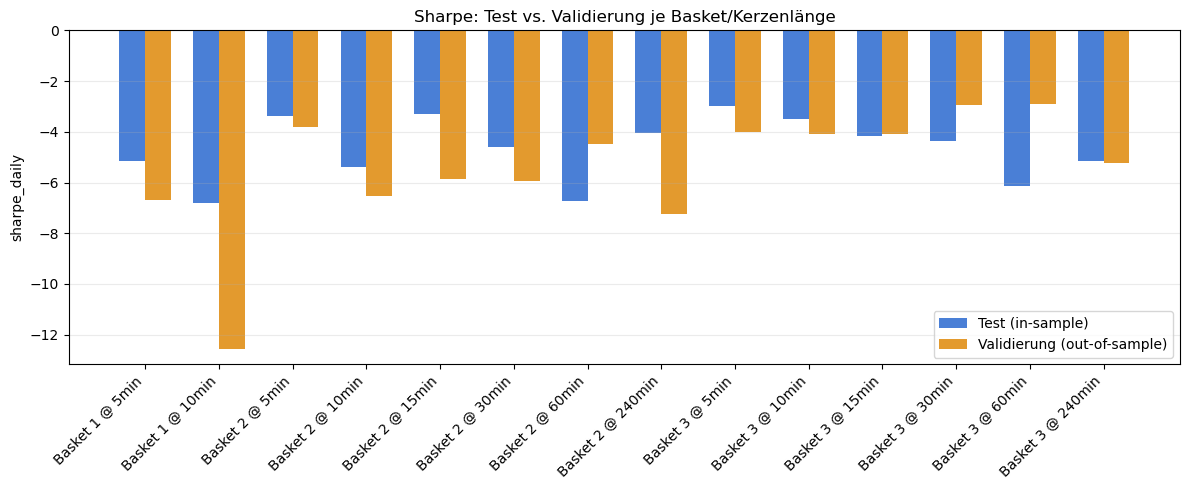

In [13]:
def build_overfit_df(test_results: dict, validation_results: dict) -> pd.DataFrame:
    '''Baut die Test-vs-Validierung-Kennzahlentabelle (Sharpe/CAGR/MaxDD/Trades je
    Kombination) aus zwei {(basket, candle_minutes): BacktestResult}-Dicts.'''
    rows = []
    for key, test_result in test_results.items():
        validation_result = validation_results[key]
        basket, candle_minutes = key
        rows.append({
            "basket": basket, "candle_minutes": candle_minutes,
            "sharpe_test": test_result.metrics.get("sharpe_daily", np.nan),
            "sharpe_validation": validation_result.metrics.get("sharpe_daily", np.nan),
            "cagr_test": test_result.metrics.get("cagr_daily", np.nan),
            "cagr_validation": validation_result.metrics.get("cagr_daily", np.nan),
            "max_dd_test": test_result.metrics.get("max_drawdown_pct", np.nan),
            "max_dd_validation": validation_result.metrics.get("max_drawdown_pct", np.nan),
            "n_trades_test": test_result.metrics.get("n_trades", 0),
            "n_trades_validation": validation_result.metrics.get("n_trades", 0),
        })
    df = pd.DataFrame(rows)
    df["sharpe_validation_minus_test"] = df["sharpe_validation"] - df["sharpe_test"]
    return df.sort_values(["basket", "candle_minutes"]).reset_index(drop=True)


def _combo_labels(df: pd.DataFrame) -> pd.Series:
    return df["basket"].astype(str) + " @ " + df["candle_minutes"].astype(str) + "min"


def plot_overfit_bars(overfit_df: pd.DataFrame, *, title: str | None = None, ax=None):
    '''Balkendiagramm Sharpe Test vs. Validierung je Kombination.'''
    own_fig = ax is None
    if own_fig:
        fig, ax = plt.subplots(figsize=(12, 5))
    x = np.arange(len(overfit_df))
    width = 0.35
    labels = _combo_labels(overfit_df)
    ax.bar(x - width / 2, overfit_df["sharpe_test"], width, label="Test (in-sample)", color="#4a7fd6")
    ax.bar(x + width / 2, overfit_df["sharpe_validation"], width, label="Validierung (out-of-sample)", color="#e39a2e")
    ax.axhline(0, color="black", linewidth=0.6)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=45, ha="right")
    ax.set_ylabel("sharpe_daily")
    if title:
        ax.set_title(title)
    ax.legend()
    ax.grid(True, alpha=0.25, axis="y")
    if own_fig:
        plt.tight_layout()
        plt.show()


def plot_risk_scatter(metrics_df: pd.DataFrame, *, title: str | None = None, ax=None):
    '''Scatter Rendite (CAGR) vs. |Max Drawdown|, Farbe = Sharpe.'''
    own_fig = ax is None
    if own_fig:
        fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(
        metrics_df["max_drawdown_pct"].abs(), metrics_df["cagr_daily"],
        s=80, c=metrics_df["sharpe_daily"], cmap="RdYlGn", edgecolor="black",
    )
    for _, row in metrics_df.iterrows():
        ax.annotate(
            f"{row['basket'].replace('Basket ', 'B')}@{int(row['candle_minutes'])}m",
            (abs(row["max_drawdown_pct"]), row["cagr_daily"]), fontsize=7,
            xytext=(4, 4), textcoords="offset points",
        )
    ax.set_xlabel("|Max Drawdown|")
    ax.set_ylabel("CAGR (annualisiert)")
    if title:
        ax.set_title(title)
    ax.grid(True, alpha=0.25)
    if own_fig:
        plt.tight_layout()
        plt.show()


def plot_trades_vs_sharpe(validation_results: dict, *, title_suffix: str = ""):
    '''Zwei Ansichten von Trade-Frequenz vs. Sharpe: (1) Balken+Linie je Kombination,
    (2) Scatter mit Basket als Farbe.'''
    rows = [{
        "basket": basket, "candle_minutes": candle_minutes,
        "n_trades": result.metrics.get("n_trades", np.nan),
        "sharpe_daily": result.metrics.get("sharpe_daily", np.nan),
    } for (basket, candle_minutes), result in validation_results.items()]
    trades_df = pd.DataFrame(rows).sort_values(["basket", "candle_minutes"]).reset_index(drop=True)
    labels = _combo_labels(trades_df)
    x = np.arange(len(trades_df))

    fig, ax_trades = plt.subplots(figsize=(14, 5))
    ax_trades.bar(x, trades_df["n_trades"], color="#4a7fd6", alpha=0.7, label="Anzahl Trades")
    ax_trades.set_xticks(x)
    ax_trades.set_xticklabels(labels, rotation=45, ha="right")
    ax_trades.set_ylabel("Anzahl Trades", color="#4a7fd6")
    ax_trades.tick_params(axis="y", labelcolor="#4a7fd6")
    ax_trades.grid(True, alpha=0.25, axis="y")
    ax_sharpe_t = ax_trades.twinx()
    ax_sharpe_t.plot(x, trades_df["sharpe_daily"], color="#e34a33", marker="o", linewidth=2, label="Sharpe Ratio")
    ax_sharpe_t.axhline(0, color="#e34a33", linewidth=0.6, linestyle="--", alpha=0.5)
    ax_sharpe_t.set_ylabel("Sharpe Ratio (daily)", color="#e34a33")
    ax_sharpe_t.tick_params(axis="y", labelcolor="#e34a33")
    if title_suffix:
        ax_trades.set_title(f"Anzahl Trades vs. Sharpe{title_suffix}")
    lines_1, labels_1 = ax_trades.get_legend_handles_labels()
    lines_2, labels_2 = ax_sharpe_t.get_legend_handles_labels()
    ax_trades.legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper left", fontsize=8, frameon=False)
    plt.tight_layout()
    plt.show()

    basket_colors = {"Basket 1": "#4a7fd6", "Basket 2": "#e39a2e", "Basket 3": "#2ea36c"}
    fig, ax_scatter = plt.subplots(figsize=(8, 5.5))
    for basket, group in trades_df.groupby("basket"):
        ax_scatter.scatter(
            group["n_trades"], group["sharpe_daily"],
            s=80, color=basket_colors.get(basket, "#999999"), edgecolor="black", label=basket,
        )
    for _, row in trades_df.iterrows():
        ax_scatter.annotate(
            f"{int(row['candle_minutes'])}m", (row["n_trades"], row["sharpe_daily"]),
            fontsize=7, xytext=(4, 4), textcoords="offset points",
        )
    ax_scatter.axhline(0, color="black", linewidth=0.6)
    ax_scatter.set_xlabel("Anzahl Trades")
    ax_scatter.set_ylabel("Sharpe Ratio (daily)")
    if title_suffix:
        ax_scatter.set_title(f"Trades vs. Sharpe je Basket{title_suffix}")
    ax_scatter.grid(True, alpha=0.25)
    ax_scatter.legend(frameon=False)
    plt.tight_layout()
    plt.show()


overfit_df = build_overfit_df(TEST_RESULTS, VALIDATION_RESULTS)
display(overfit_df)
plot_overfit_bars(overfit_df, title="Sharpe: Test vs. Validierung je Basket/Kerzenlänge")

## 8. Equity-Kurven (normiert) -- alle Kombinationen, Validierungsfenster

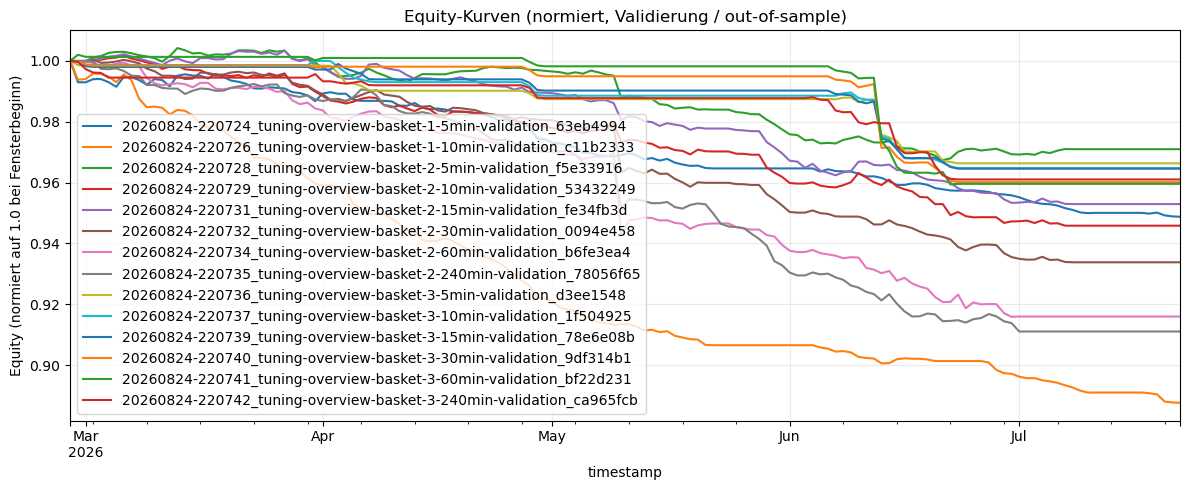

In [14]:
curves = bt_runs.compare_equity_curves(VALIDATION_RUN_IDS)
if not curves.empty:
    ax = curves.plot(figsize=(12, 5), title="Equity-Kurven (normiert, Validierung / out-of-sample)")
    ax.set_ylabel("Equity (normiert auf 1.0 bei Fensterbeginn)")
    ax.grid(True, alpha=0.25)
    plt.tight_layout()
    plt.show()
else:
    print("Keine Equity-Kurven zum Plotten (leere Trades in allen Validierungs-Runs?).")

## 9. Equity & Drawdown je Kombination (Validierung)


### Basket 1 @ 5min (Validierung)


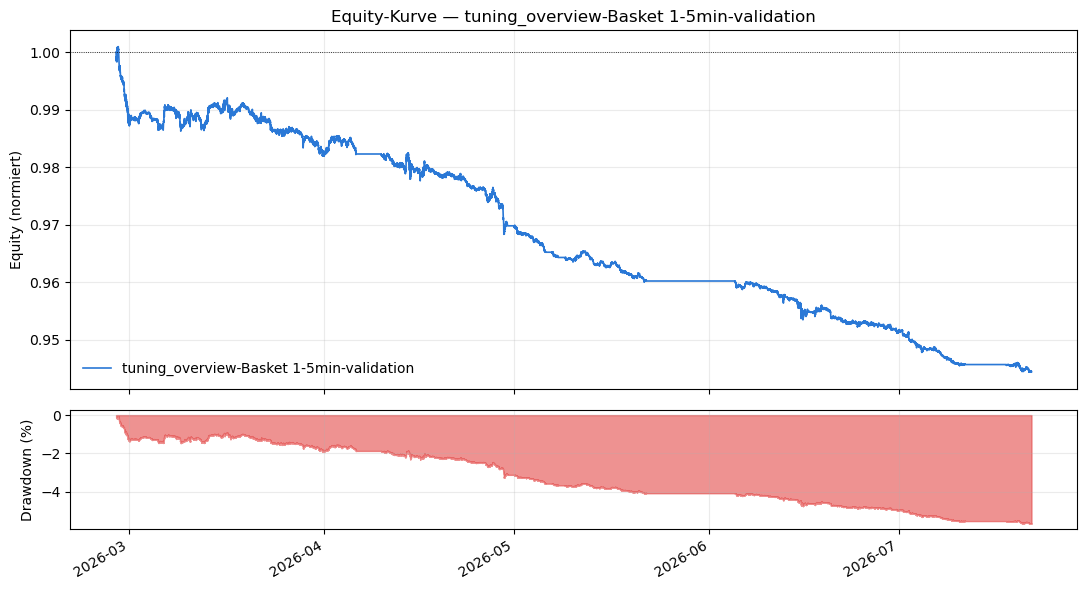


### Basket 1 @ 10min (Validierung)


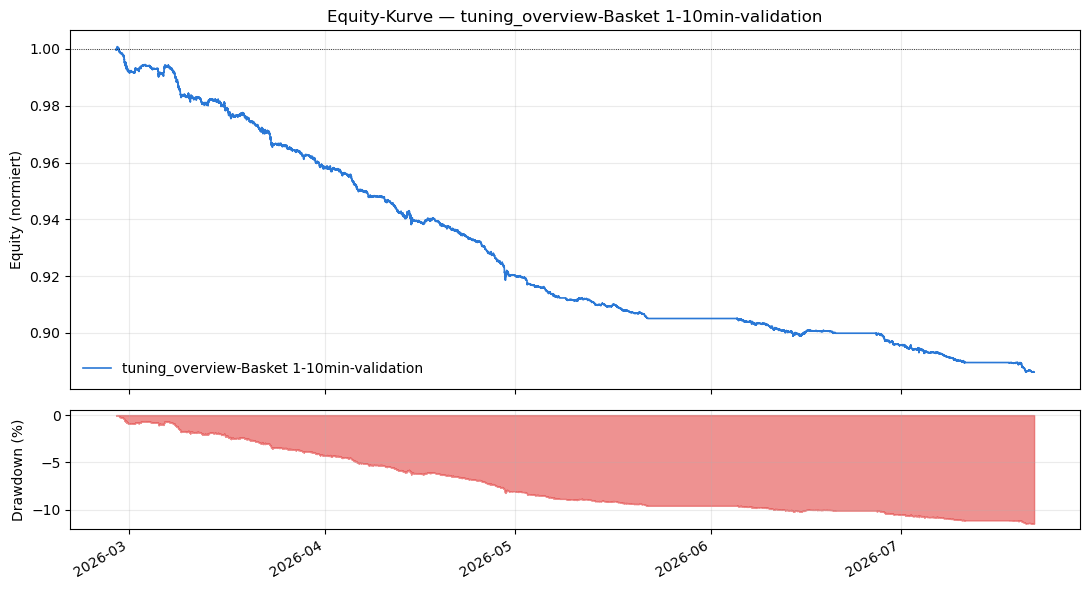


### Basket 2 @ 5min (Validierung)


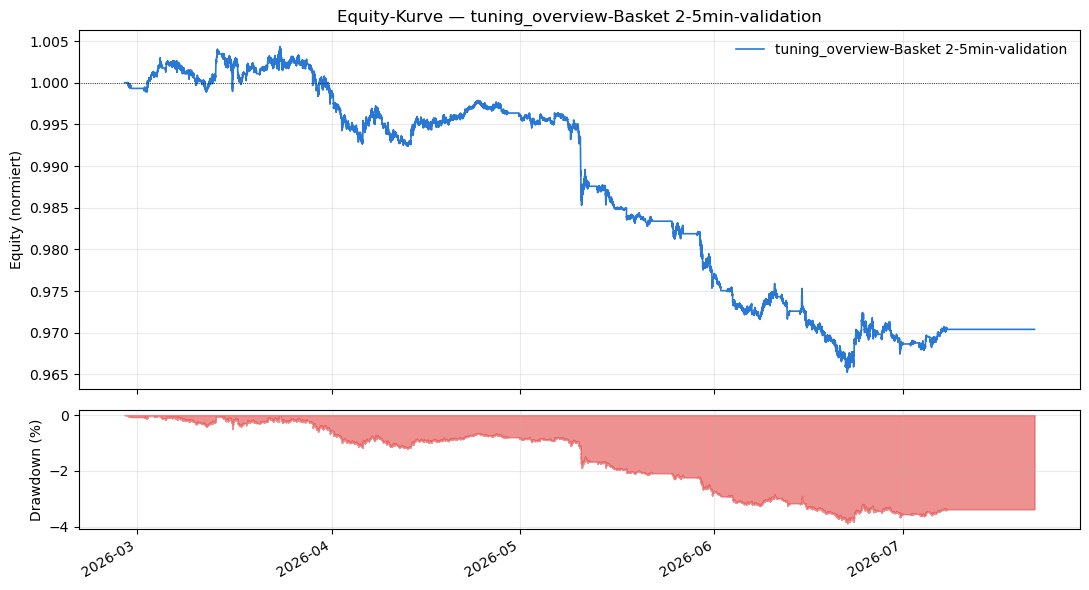


### Basket 2 @ 10min (Validierung)


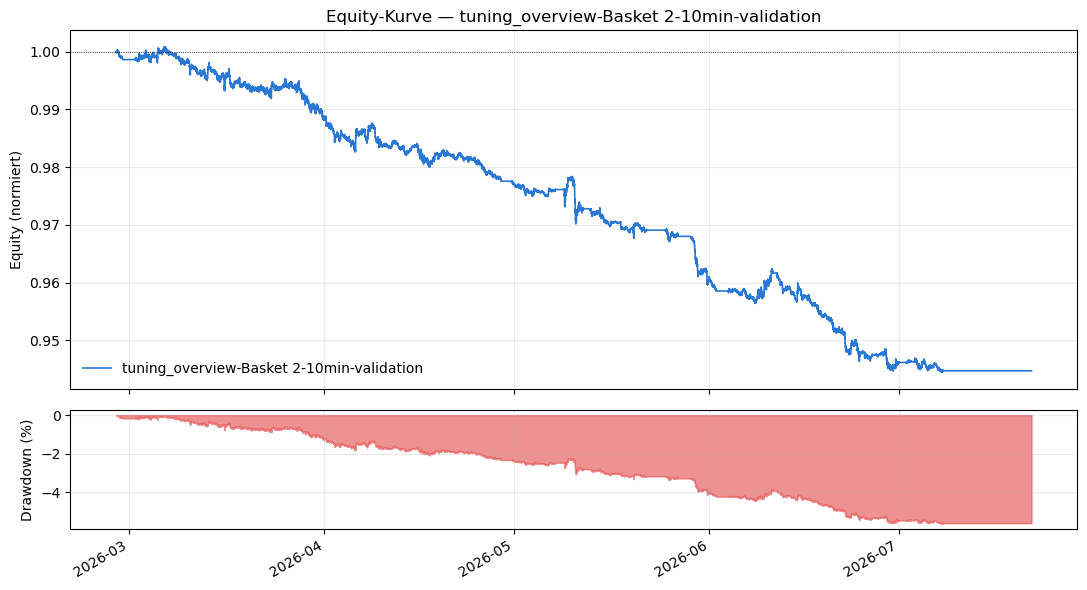


### Basket 2 @ 15min (Validierung)


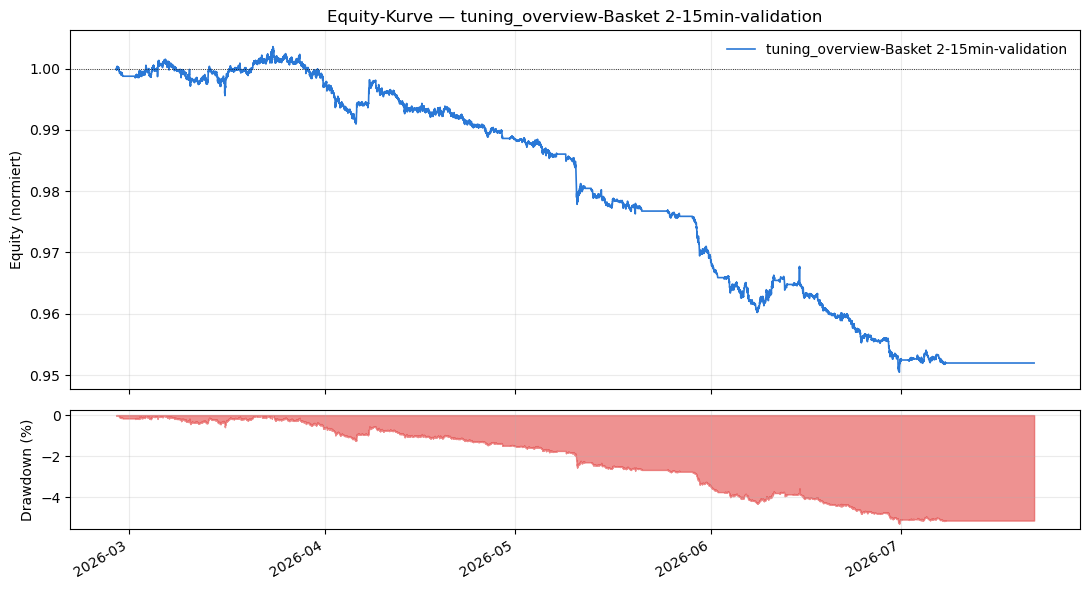


### Basket 2 @ 30min (Validierung)


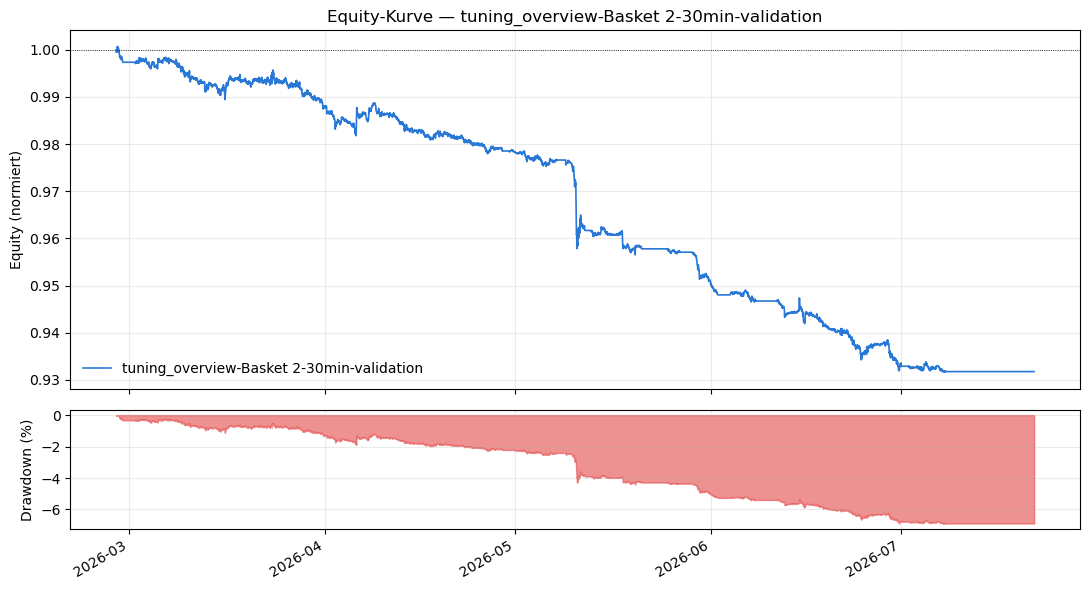


### Basket 2 @ 60min (Validierung)


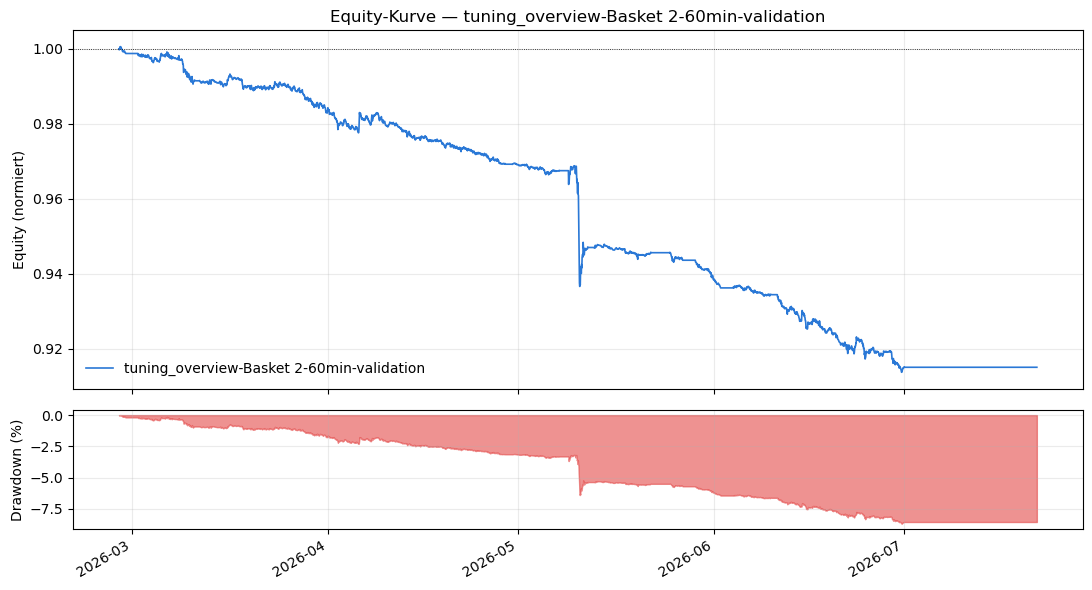


### Basket 2 @ 240min (Validierung)


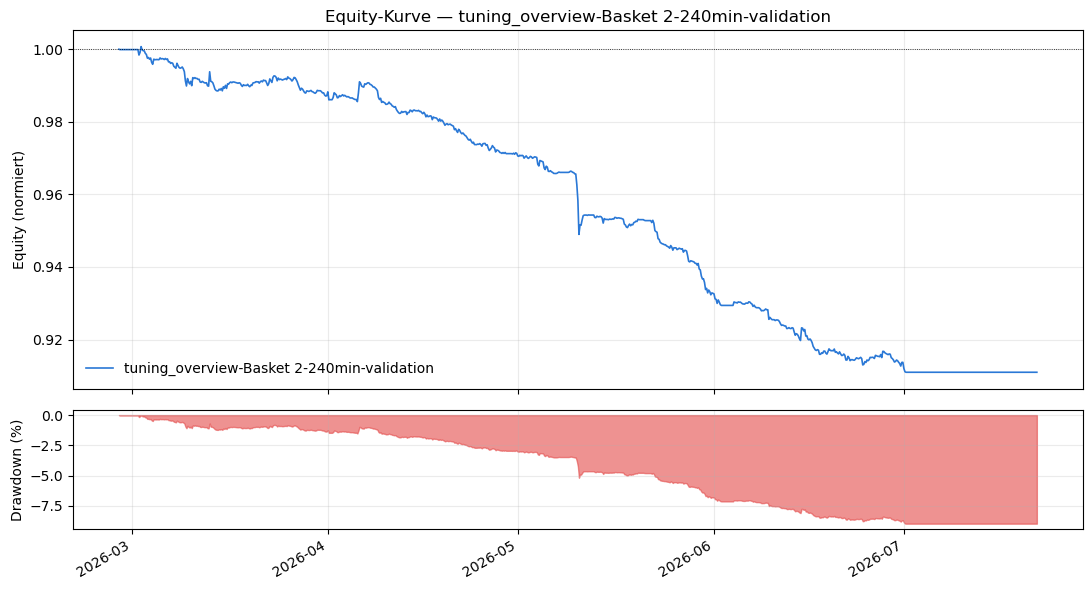


### Basket 3 @ 5min (Validierung)


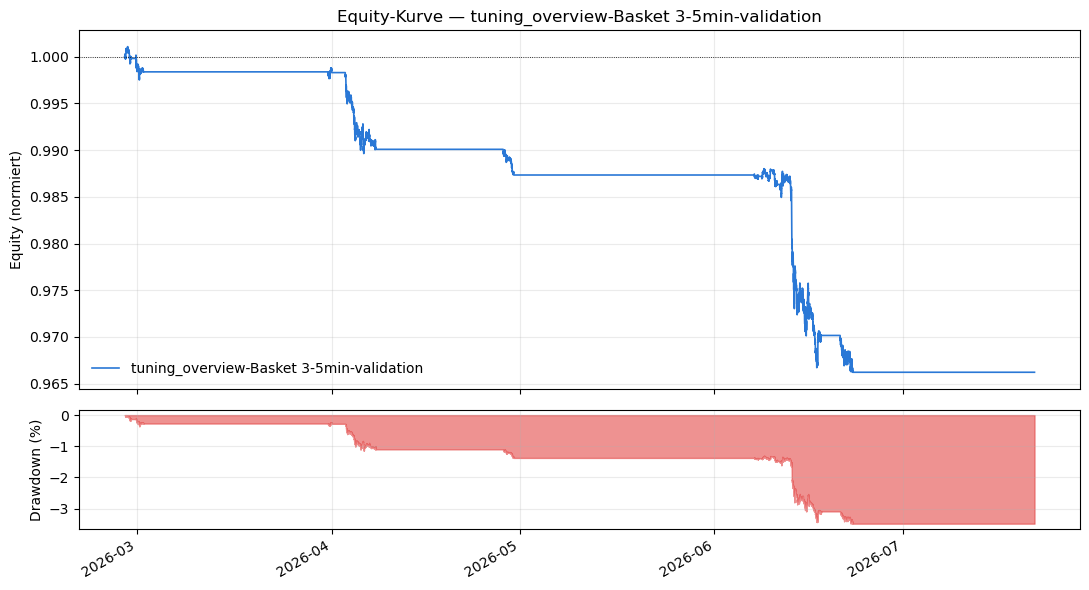


### Basket 3 @ 10min (Validierung)


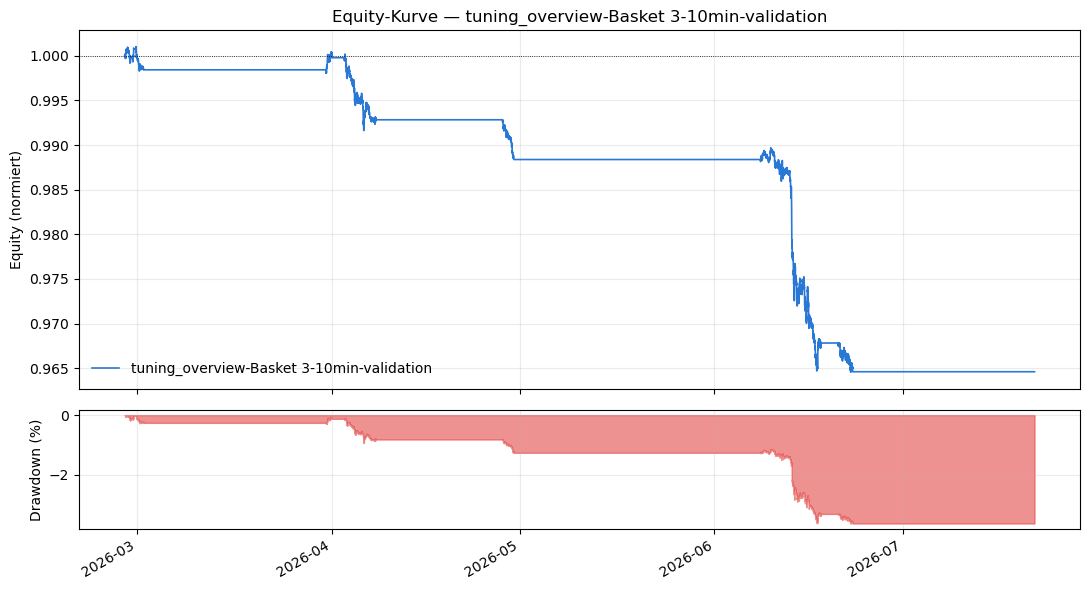


### Basket 3 @ 15min (Validierung)


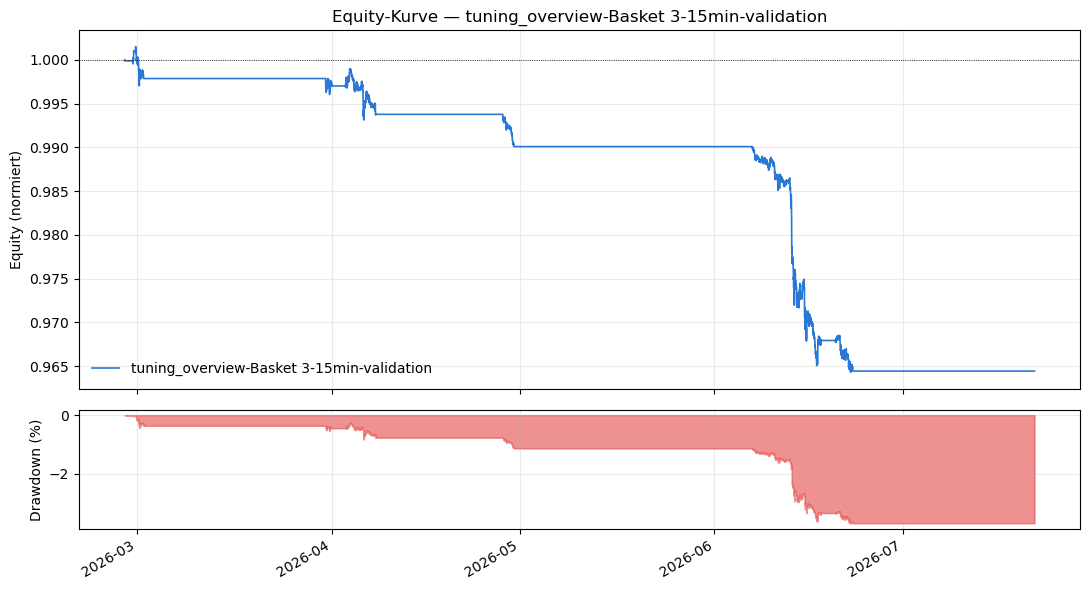


### Basket 3 @ 30min (Validierung)


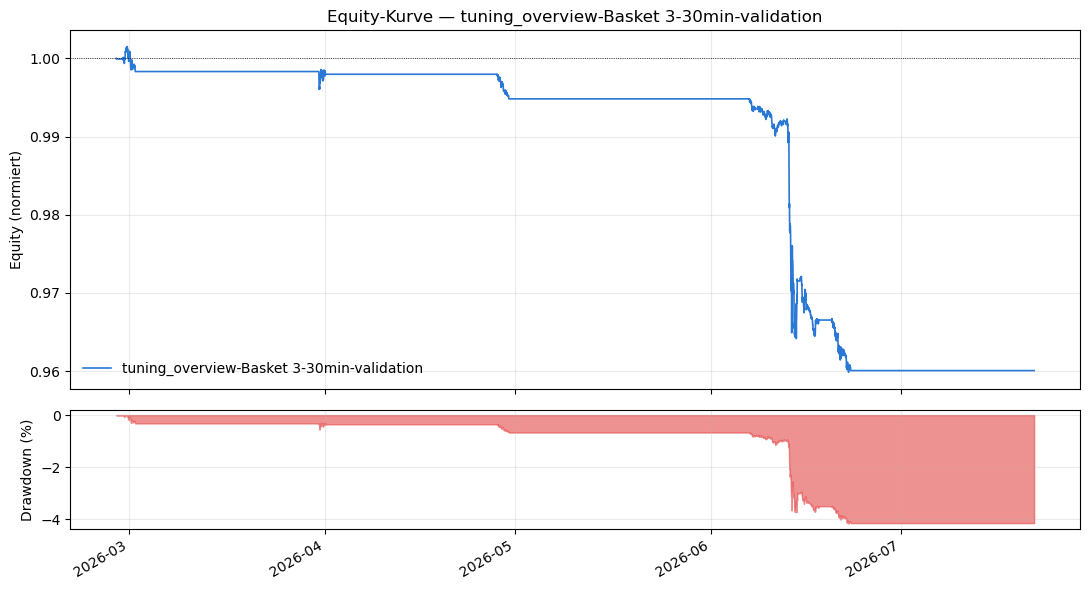


### Basket 3 @ 60min (Validierung)


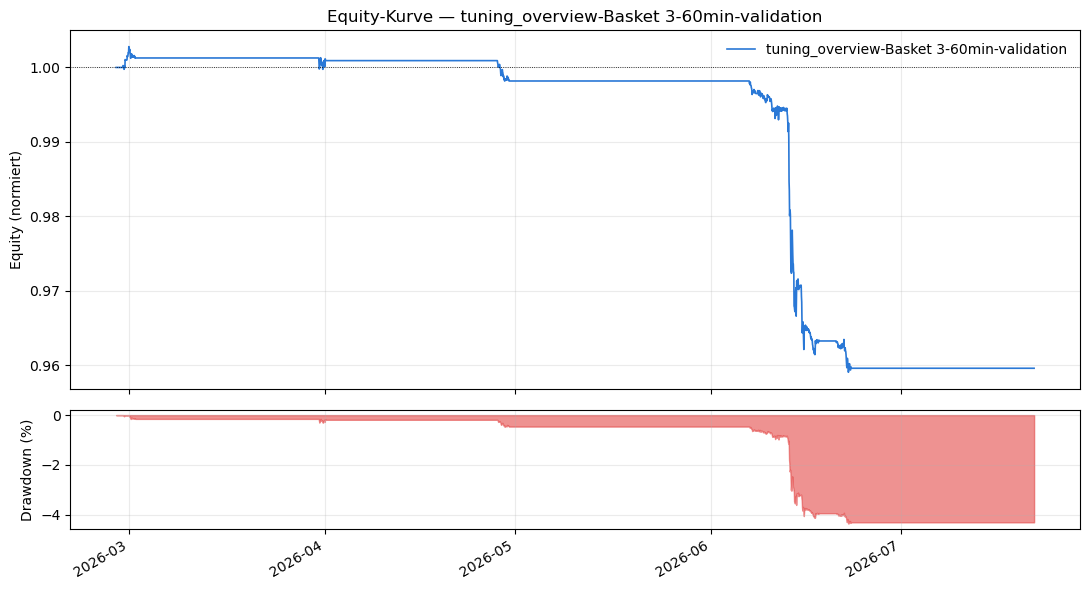


### Basket 3 @ 240min (Validierung)


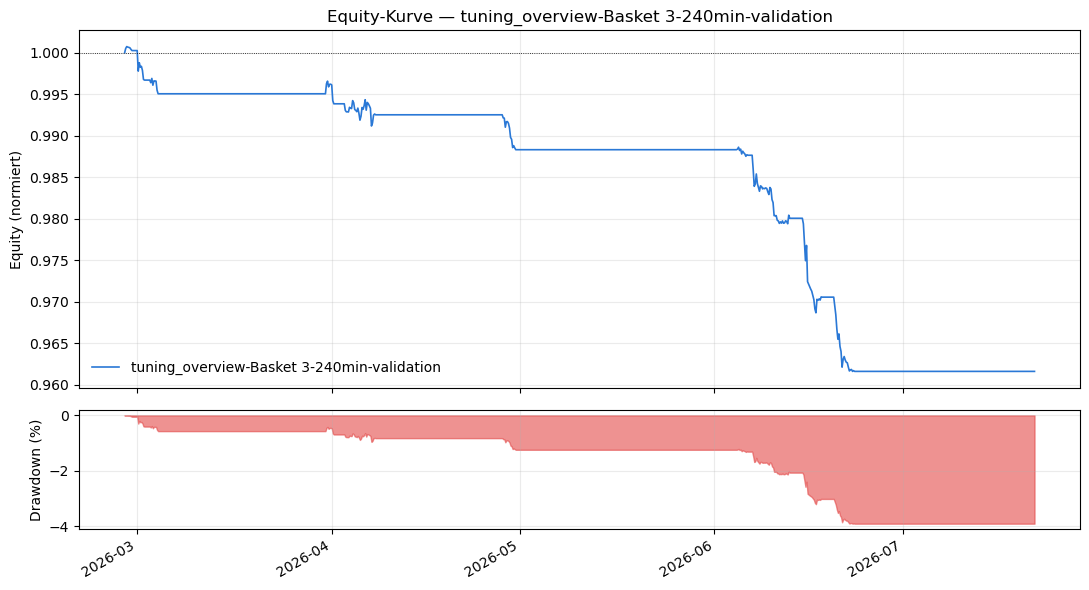

In [15]:
for (basket, candle_minutes), result in VALIDATION_RESULTS.items():
    if result.equity_curve.empty:
        print(f"{basket} @ {candle_minutes}min: keine Trades in der Validierung, kein Plot.")
        continue
    print(f"\n### {basket} @ {candle_minutes}min (Validierung)")
    bt_plots.plot_equity_and_drawdown(result, benchmark_close=None)

## 10. Trade-Verteilung nach Exit-Grund

In [16]:
print("### Validierung (out-of-sample)")
display(bt_runs.compare_trade_distributions(VALIDATION_RUN_IDS))

print("\n### Test (in-sample)")
display(bt_runs.compare_trade_distributions(TEST_RUN_IDS))

### Validierung (out-of-sample)


,exit_reason,count,mean,sum,run_id
0,clique_break,25,-54.693101,-1367.327532,20260824-220724_tuning-overview-basket-1-5min-...
1,end_of_backtest,1,-18.798863,-18.798863,20260824-220724_tuning-overview-basket-1-5min-...
2,max_holding_days,1,-232.676818,-232.676818,20260824-220724_tuning-overview-basket-1-5min-...
3,stop,9,-132.991493,-1196.923439,20260824-220724_tuning-overview-basket-1-5min-...
4,target,232,-7.566216,-1755.362207,20260824-220724_tuning-overview-basket-1-5min-...
5,clique_break,29,-55.427309,-1607.391969,20260824-220726_tuning-overview-basket-1-10min...
6,end_of_backtest,1,-14.801285,-14.801285,20260824-220726_tuning-overview-basket-1-10min...
7,max_holding_days,1,-67.172076,-67.172076,20260824-220726_tuning-overview-basket-1-10min...
8,stop,5,-81.921511,-409.607554,20260824-220726_tuning-overview-basket-1-10min...
9,target,416,-14.620971,-6082.324076,20260824-220726_tuning-overview-basket-1-10min...



### Test (in-sample)


,exit_reason,count,mean,sum,run_id
0,clique_break,173,-53.638055,-9279.383590,20260824-220711_tuning-overview-basket-1-5min-...
1,stop,49,-117.648950,-5764.798574,20260824-220711_tuning-overview-basket-1-5min-...
2,target,639,-3.931256,-2512.072669,20260824-220711_tuning-overview-basket-1-5min-...
3,clique_break,160,-54.474512,-8715.921875,20260824-220726_tuning-overview-basket-1-10min...
4,max_holding_days,1,-204.731527,-204.731527,20260824-220726_tuning-overview-basket-1-10min...
5,stop,25,-92.339302,-2308.482555,20260824-220726_tuning-overview-basket-1-10min...
6,target,1115,-15.120765,-16859.652920,20260824-220726_tuning-overview-basket-1-10min...
7,clique_break,377,-49.835958,-18788.155997,20260824-220727_tuning-overview-basket-2-5min-...
8,max_holding_days,2,-183.989742,-367.979484,20260824-220727_tuning-overview-basket-2-5min-...
9,stop,62,-95.145615,-5899.028156,20260824-220727_tuning-overview-basket-2-5min-...


## 11. Exit-Gründe & PnL-Verteilung je Kombination (Validierung)


### Basket 1 @ 5min (Validierung)


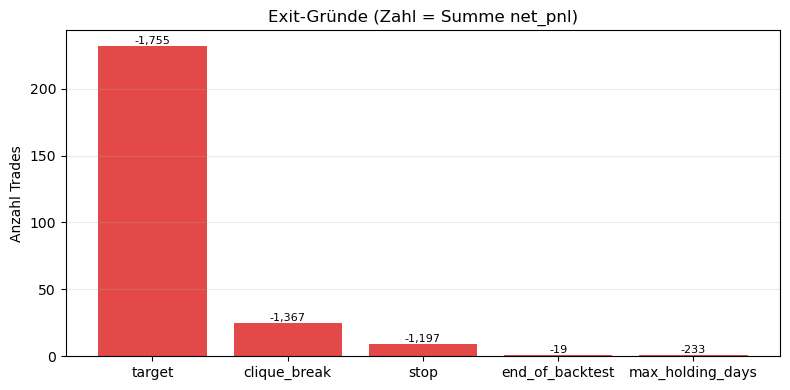

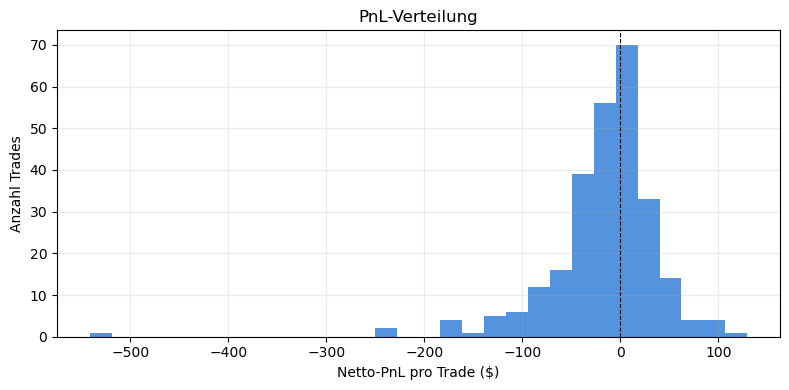


### Basket 1 @ 10min (Validierung)


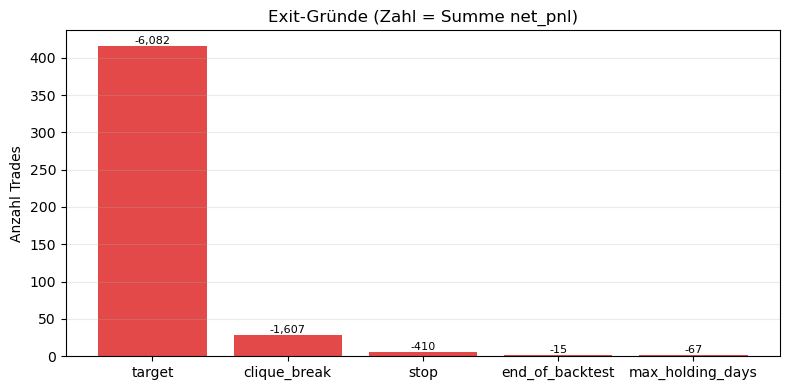

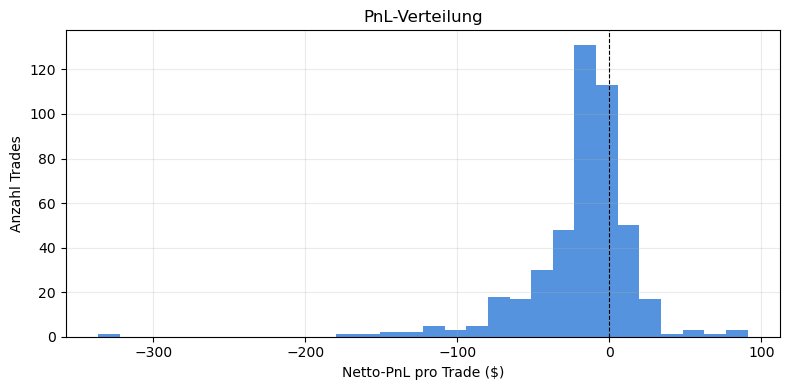


### Basket 2 @ 5min (Validierung)


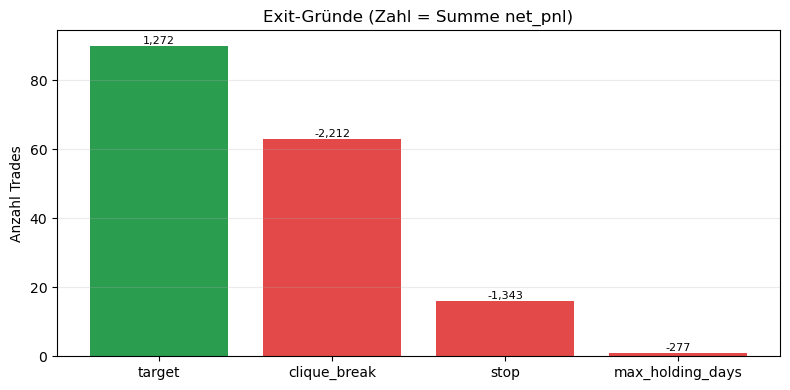

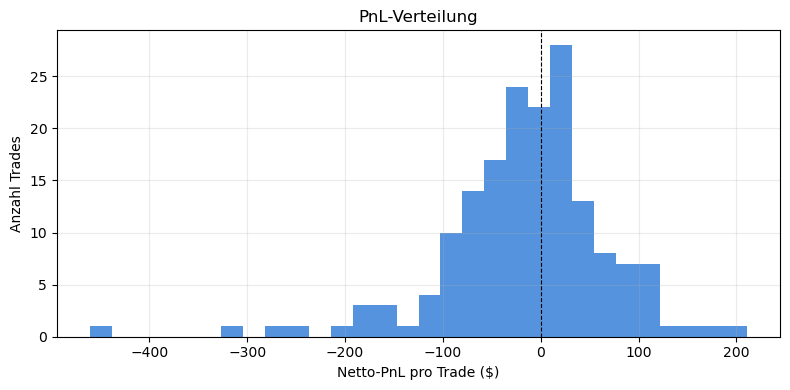


### Basket 2 @ 10min (Validierung)


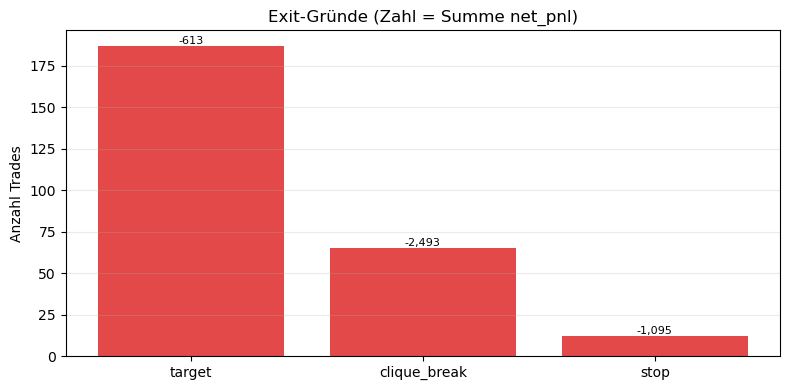

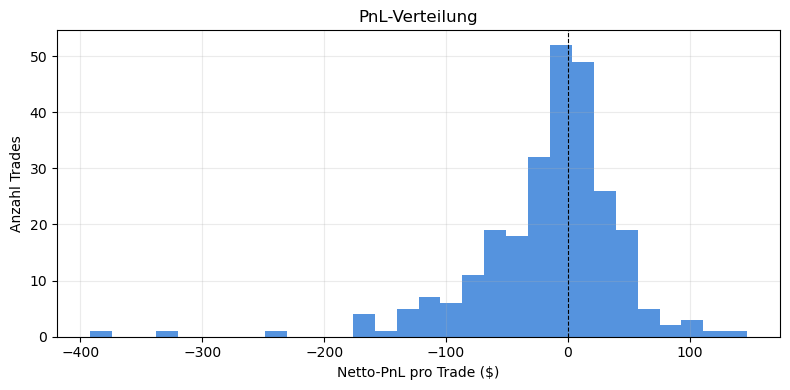


### Basket 2 @ 15min (Validierung)


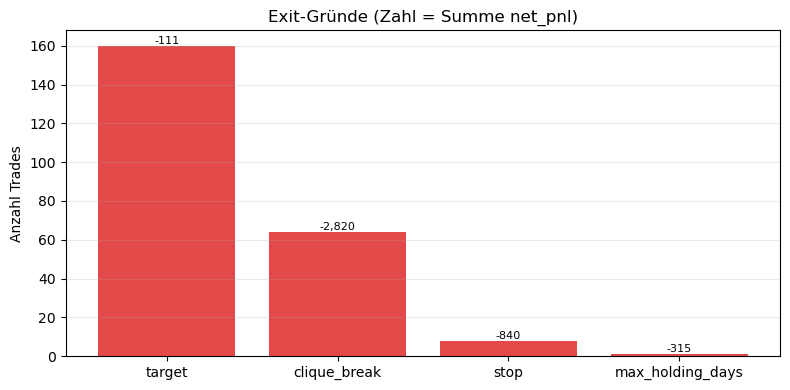

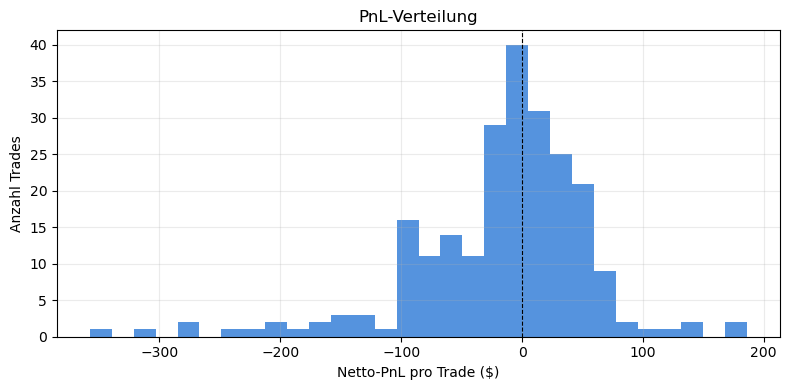


### Basket 2 @ 30min (Validierung)


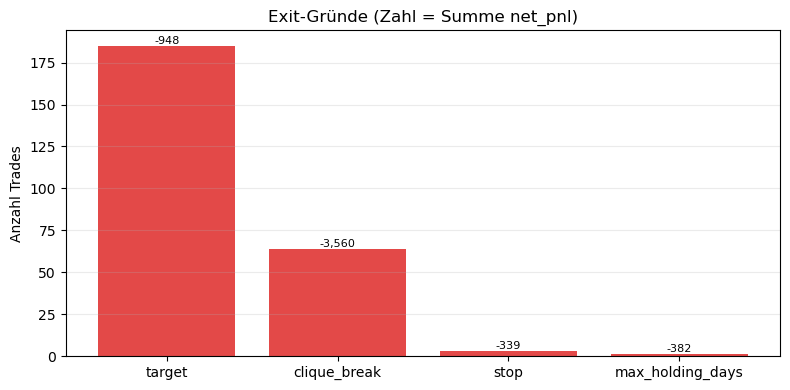

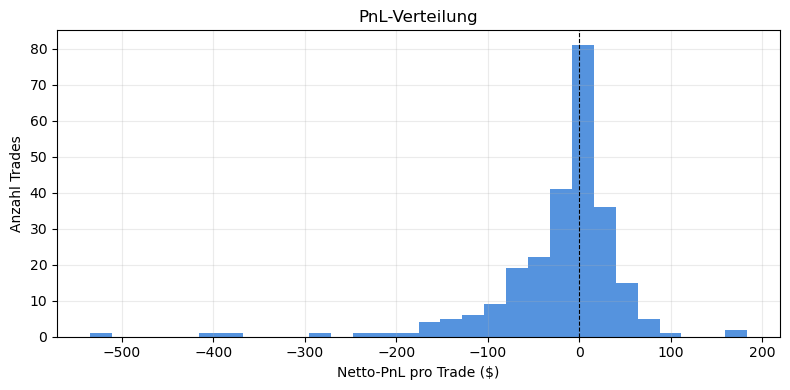


### Basket 2 @ 60min (Validierung)


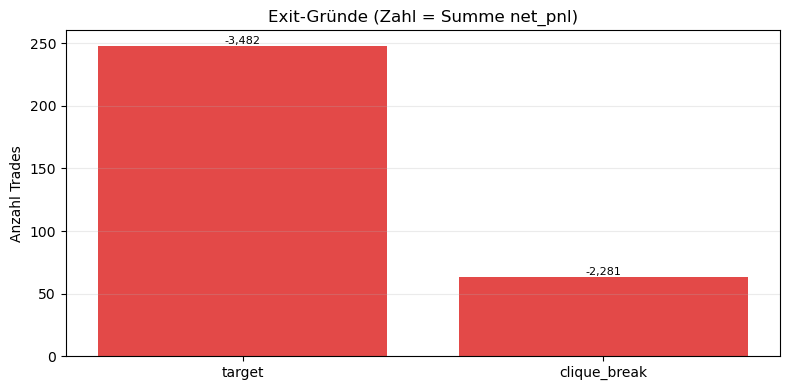

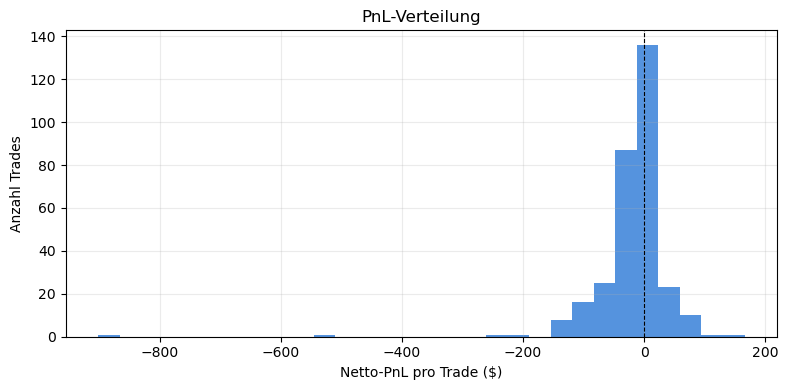


### Basket 2 @ 240min (Validierung)


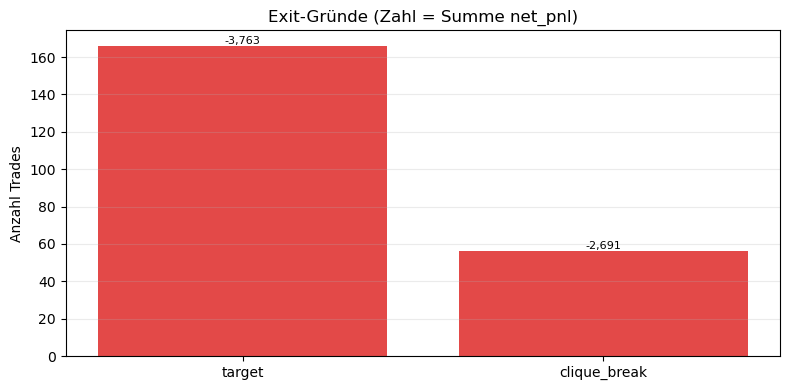

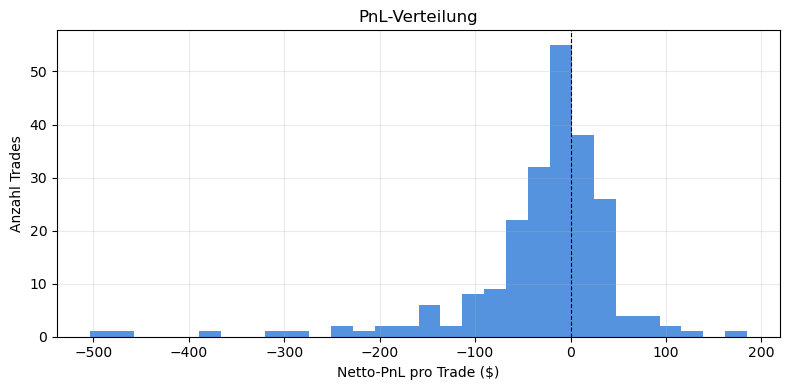


### Basket 3 @ 5min (Validierung)


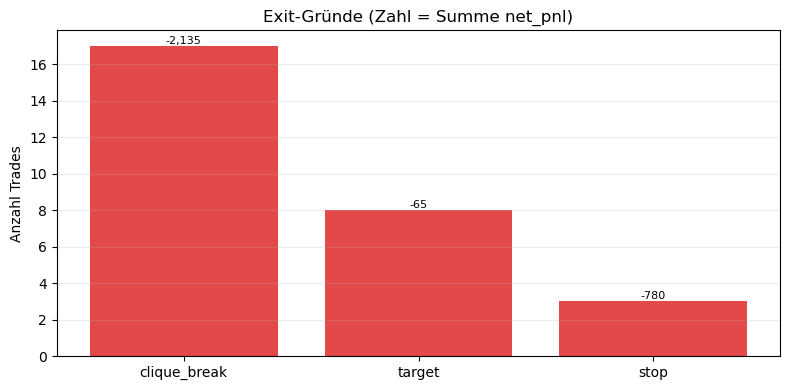

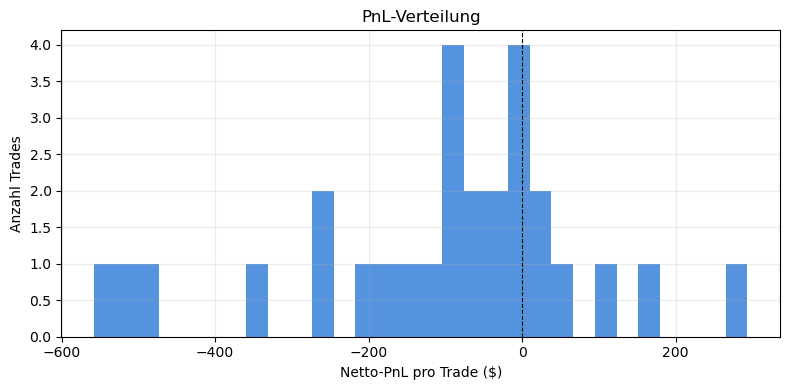


### Basket 3 @ 10min (Validierung)


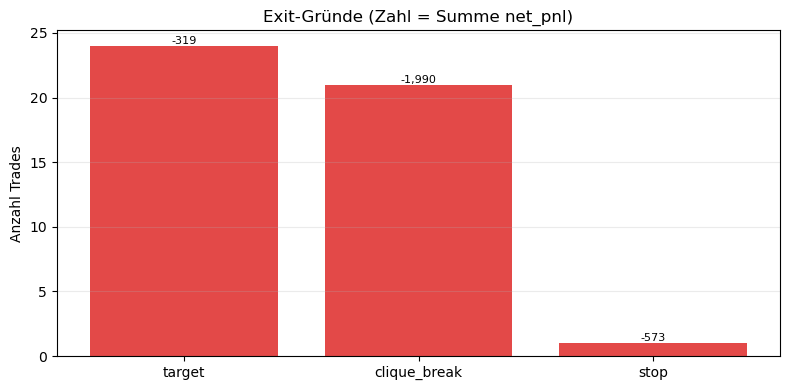

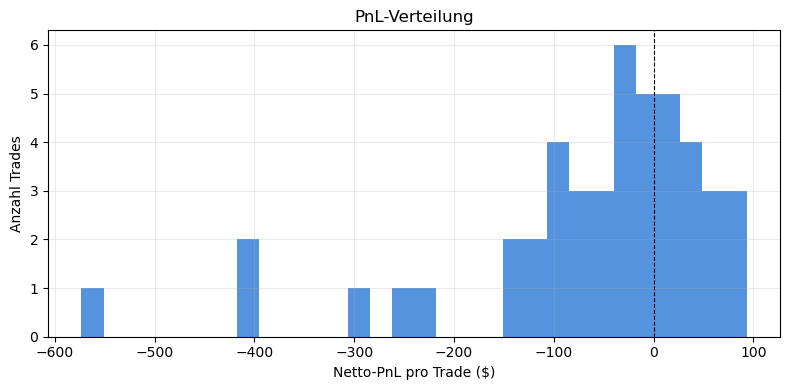


### Basket 3 @ 15min (Validierung)


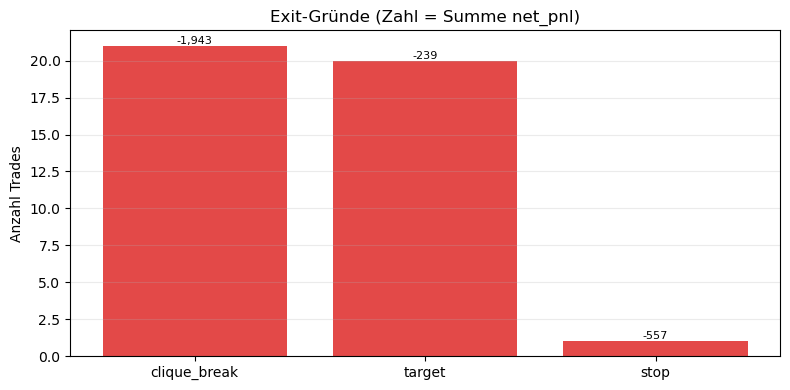

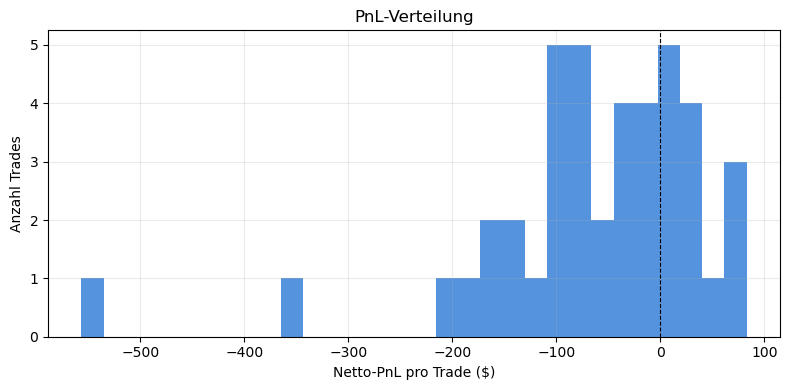


### Basket 3 @ 30min (Validierung)


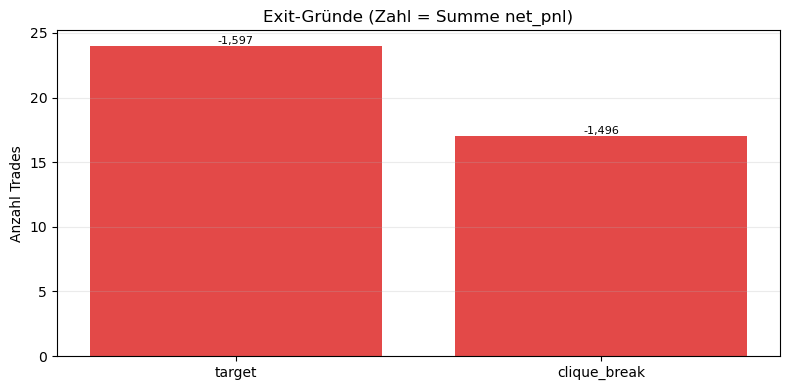

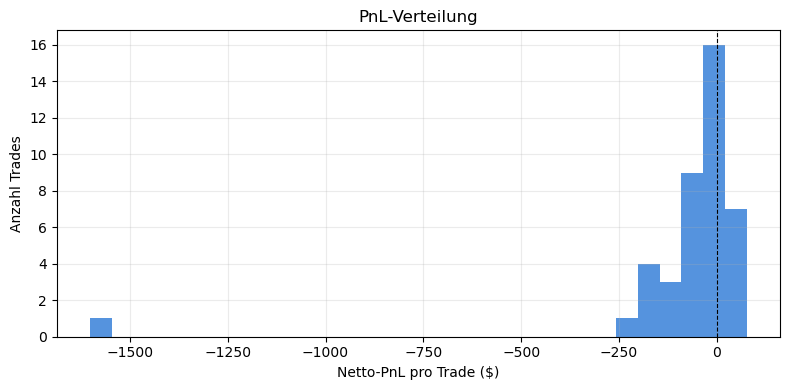


### Basket 3 @ 60min (Validierung)


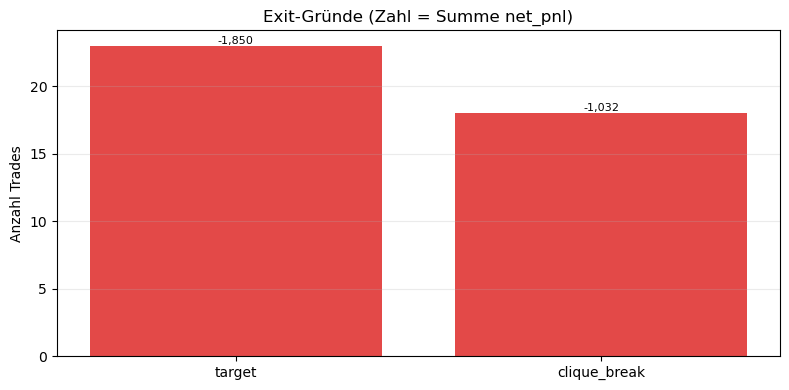

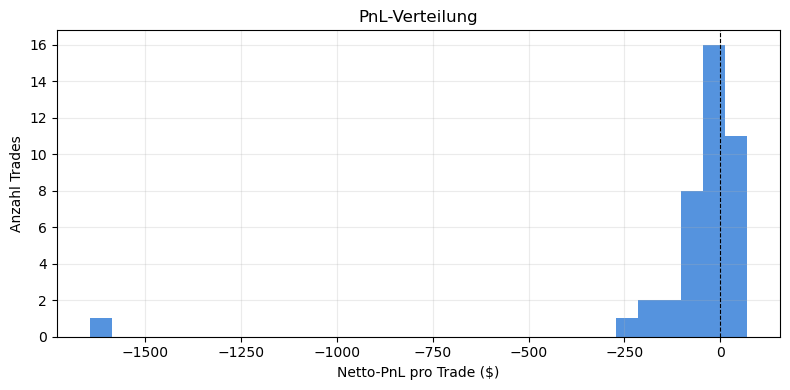


### Basket 3 @ 240min (Validierung)


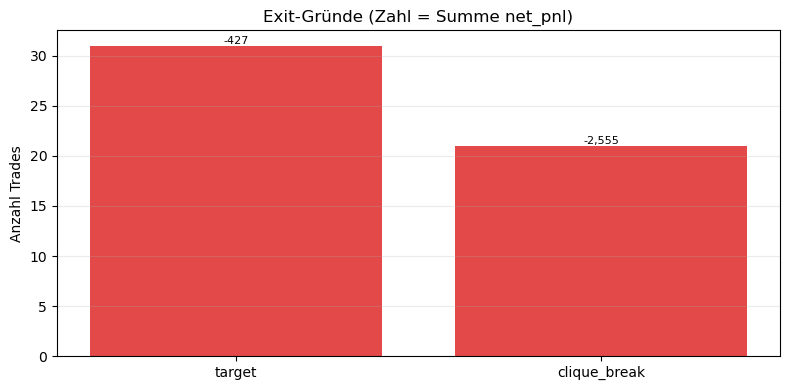

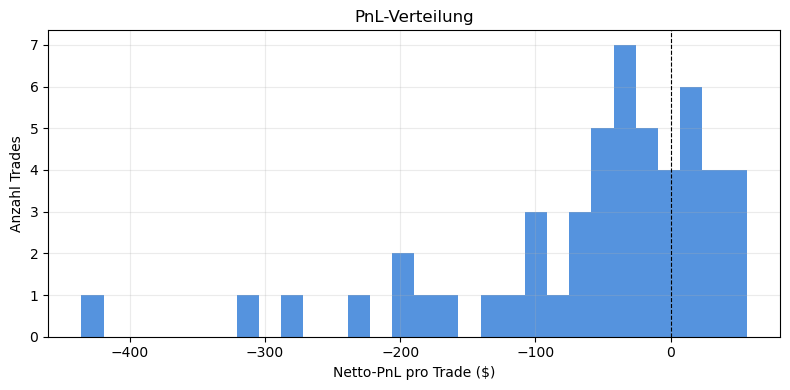

In [17]:
for (basket, candle_minutes), result in VALIDATION_RESULTS.items():
    if result.trades.empty:
        continue
    print(f"\n### {basket} @ {candle_minutes}min (Validierung)")
    bt_plots.plot_exit_reason_breakdown(result.trades)
    bt_plots.plot_pnl_distribution(result.trades)

## 11b. Vola-Regime-Verteilung der Trades

Wie viele Trades wurden in welchem Vola-Regime eröffnet (Low/Normal/High, siehe PDF A.2 --
`src.backtest.strategy._resolve_entry_threshold_and_sizing`)? Regime wird pro Trade aus
`entry_threshold_z` (dem bei Entry tatsächlich gültigen, ggf. regimeabhängig verschobenen
Schwellenwert, siehe `src/backtest/portfolio.py`) im Vergleich zum Basis-`entry_z` des
jeweiligen Baskets abgeleitet: `entry_threshold_z < entry_z` → Low-Vol (engere Schwelle),
`entry_threshold_z > entry_z` → High-Vol (weitere Schwelle), sonst Normal (oder
`dynamic_threshold_enabled=False`).

`make_regime_widget(...)` baut das interaktive Panel für ein beliebiges Validation-Result-Dict
-- wird unten für den Netto-Lauf aufgerufen, in Abschnitt 8 (Kostenszenarien) erneut für
jedes Szenario aus `COST_SCENARIOS`, statt eines eigenen Kopie-Widgets pro Szenario.

In [18]:
def _classify_trade_regime(trades: pd.DataFrame, config: BacktestConfig) -> pd.Series:
    '''entry_threshold_z vs. params_for(basket).entry_z -> "low"/"normal"/"high" pro Trade.
    Toleranz 1e-9 gegen Float-Rundung (z.B. entry_threshold_z == entry_z nach einem
    max(..., 0.1)-Clamp in _resolve_entry_threshold_and_sizing).'''
    if trades.empty:
        return pd.Series(dtype=str)

    def _regime_for_row(row):
        base_entry_z = config.params_for(row["basket"]).entry_z
        delta = row["entry_threshold_z"] - base_entry_z
        if delta < -1e-9:
            return "low"
        if delta > 1e-9:
            return "high"
        return "normal"

    return trades.apply(_regime_for_row, axis=1)


def make_regime_widget(validation_results: dict, *, title: str, title_suffix: str = ""):
    '''Baut + zeigt ein interaktives Basket/Kerzenlaenge-Dropdown-Paar samt
    Vola-Regime-Uebersicht (Tabelle + zwei Balkendiagramme) fuer validation_results.'''
    w_basket = widgets.Dropdown(
        options=["(alle)"] + sorted({b for b, _ in validation_results}), value="(alle)",
        description="Basket:", style={"description_width": "140px"},
    )
    w_candle = widgets.Dropdown(
        options=["(alle)"] + sorted({cm for _, cm in validation_results}), value="(alle)",
        description="Kerzenlänge (min):", style={"description_width": "140px"},
    )
    w_output = widgets.Output()

    def _update(*_change):
        with w_output:
            clear_output(wait=True)
            rows = []
            for (basket, candle_minutes), result in validation_results.items():
                if w_basket.value != "(alle)" and basket != w_basket.value:
                    continue
                if w_candle.value != "(alle)" and candle_minutes != w_candle.value:
                    continue
                if result.trades.empty:
                    continue
                regimes = _classify_trade_regime(result.trades, result.config)
                counts = regimes.value_counts().reindex(["low", "normal", "high"], fill_value=0)
                pnl_by_regime = result.trades.assign(regime=regimes).groupby("regime")["net_pnl"].sum().reindex(["low", "normal", "high"], fill_value=0.0)
                for regime in ("low", "normal", "high"):
                    rows.append({
                        "basket": basket, "candle_minutes": candle_minutes, "regime": regime,
                        "n_trades": int(counts[regime]), "net_pnl": float(pnl_by_regime[regime]),
                    })
            regime_df = pd.DataFrame(rows)
            if regime_df.empty:
                print("Keine Trades für diese Auswahl.")
                return

            pivot_counts = regime_df.pivot_table(index=["basket", "candle_minutes"], columns="regime", values="n_trades", fill_value=0)
            pivot_counts = pivot_counts.reindex(columns=["low", "normal", "high"], fill_value=0)
            display(pivot_counts)

            totals = regime_df.groupby("regime")["n_trades"].sum().reindex(["low", "normal", "high"], fill_value=0)
            fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
            colors = {"low": "#4a9fd6", "normal": "#999999", "high": "#e39a2e"}
            ax1.bar(totals.index, totals.values, color=[colors[r] for r in totals.index])
            ax1.set_ylabel("Anzahl Trades")
            ax1.set_title(f"Trades je Regime (Summe über Auswahl{title_suffix})")
            ax1.grid(True, alpha=0.25, axis="y")

            pnl_totals = regime_df.groupby("regime")["net_pnl"].sum().reindex(["low", "normal", "high"], fill_value=0.0)
            bar_colors = ["#2a9d4f" if v >= 0 else "#e34948" for v in pnl_totals.values]
            ax2.bar(pnl_totals.index, pnl_totals.values, color=bar_colors)
            ax2.axhline(0, color="black", linewidth=0.6)
            ax2.set_ylabel("net_pnl ($)")
            ax2.set_title(f"PnL je Regime (Summe über Auswahl{title_suffix})")
            ax2.grid(True, alpha=0.25, axis="y")
            plt.tight_layout()
            plt.show()

    w_basket.observe(_update, names="value")
    w_candle.observe(_update, names="value")
    display(widgets.HTML(f"<b>{title}</b>"))
    display(widgets.VBox([widgets.HBox([w_basket, w_candle]), w_output]))
    _update()


make_regime_widget(VALIDATION_RESULTS, title="Vola-Regime-Verteilung -- Netto")

HTML(value='<b>Vola-Regime-Verteilung -- Netto</b>')

## 11c. Trade-Explorer: Spread, Bollinger-Bänder, Ein-/Ausstieg & Z-Score

Interaktives Panel -- Basket/Kerzenlänge/Trade auswählen, zeigt zwei übereinander liegende
Plots für den gewählten Trade:

- **Oben:** rekonstruierter Spread mit rollierenden Bollinger-Bändern (Mittelwert ±
  `entry_z`/`exit_z`/`stop_z` · Std, siehe `src.backtest.plots.plot_trade_bollinger`) sowie
  Entry-/Exit-Markern und farblich markierter Haltedauer.
- **Unten:** derselbe Zeitraum als Z-Score-Verlauf ((Spread − Mittelwert) / Std) mit den
  relevanten Schwellenlinien (`entry_threshold_z` -- der bei DIESEM Trade tatsächlich
  gültige, ggf. regimeabhängig verschobene Wert -- sowie `exit_z`/`stop_z`), damit direkt
  sichtbar ist, bei welchem Z-Wert Entry/Exit stattfanden und wie nah am Stop die Position
  zwischenzeitlich war.

In [ ]:
from src.backtest.plots import _reconstruct_spread_band

_explorer_baskets = sorted({b for b, _ in VALIDATION_RESULTS})
w_te_basket = widgets.Dropdown(options=_explorer_baskets, value=_explorer_baskets[0] if _explorer_baskets else None, description="Basket:", style={"description_width": "140px"})
w_te_candle = widgets.Dropdown(options=sorted({cm for _, cm in VALIDATION_RESULTS}), description="Kerzenlänge (min):", style={"description_width": "140px"})
w_te_trade = widgets.Dropdown(description="Trade:", style={"description_width": "140px"}, layout=widgets.Layout(width="600px"))
w_te_buffer = widgets.IntSlider(value=144, min=24, max=576, step=24, description="Puffer (Kerzen):", style={"description_width": "140px"}, layout=widgets.Layout(width="420px"))
w_te_output = widgets.Output()


def _te_trade_label(row) -> str:
    symbols = "/".join(row["symbols"])
    return (f"{row['entry_timestamp']:%Y-%m-%d %H:%M} | {symbols} | {row['exit_reason']} | "
            f"net_pnl={row['net_pnl']:.1f}$")


def _te_update_trade_options(*_change):
    key = (w_te_basket.value, w_te_candle.value)
    result = VALIDATION_RESULTS.get(key)
    if result is None or result.trades.empty:
        w_te_trade.options = []
        return
    trades = result.trades.sort_values("entry_timestamp")
    w_te_trade.options = [(_te_trade_label(row), i) for i, row in trades.iterrows()]


def _te_plot_selected_trade(*_change):
    with w_te_output:
        clear_output(wait=True)
        key = (w_te_basket.value, w_te_candle.value)
        result = VALIDATION_RESULTS.get(key)
        if result is None or w_te_trade.value is None or result.trades.empty:
            print("Kein Trade für diese Auswahl.")
            return
        trade = result.trades.loc[w_te_trade.value]
        params = result.config.params_for(trade["basket"])
        widget_panel_te = get_panel_for_candle_minutes(w_te_candle.value)

        fig, (ax_spread, ax_z) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [3, 2]})

        bt_plots.plot_trade_bollinger(trade, widget_panel_te, params, buffer_candles=w_te_buffer.value, ax=ax_spread, show=False)

        band = _reconstruct_spread_band(
            trade, widget_panel_te, bollinger_window_candles=params.bollinger_window_candles,
            buffer_candles=w_te_buffer.value,
        )
        z_series = (band["spread"] - band["mean"]) / band["std"]

        entry_threshold_z = float(trade["entry_threshold_z"])
        ax_z.axvspan(trade["entry_timestamp"], trade["exit_timestamp"], color="#f2c94c", alpha=0.15, zorder=0)
        ax_z.plot(z_series.index, z_series.values, color="#2a78d6", linewidth=1.1, label="Z-Score", zorder=3)
        ax_z.axhline(0, color="#666666", linewidth=0.8, linestyle="--", zorder=1)

        # Entry passiert bei z=+entry_threshold_z (Short-Signal, direction=-1) ODER
        # z=-entry_threshold_z (Long-Signal, direction=+1) -- siehe generate_entries:
        # "Spread ueber Mittelwert (z>0) -> SHORT, Spread darunter (z<0) -> LONG". Beide
        # Linien werden gezeichnet (nicht nur die fuer diesen Trade tatsaechlich
        # relevante), damit sichtbar bleibt, dass das Band symmetrisch ist.
        ax_z.axhline(entry_threshold_z, color="#2a9d4f", linewidth=1.0, linestyle="-",
                     label=f"entry_threshold_z=±{entry_threshold_z:.2f}", zorder=2)
        ax_z.axhline(-entry_threshold_z, color="#2a9d4f", linewidth=1.0, linestyle="-", zorder=2)
        if not params.symmetric_exit:
            ax_z.axhline(params.exit_z, color="#4a9fd6", linewidth=1.0, linestyle="--", label=f"exit_z=±{params.exit_z:.2f}", zorder=2)
            ax_z.axhline(-params.exit_z, color="#4a9fd6", linewidth=1.0, linestyle="--", zorder=2)
        if params.stop_z is not None:
            ax_z.axhline(params.stop_z, color="#e34948", linewidth=1.0, linestyle=":", label=f"stop_z=±{params.stop_z:.2f}", zorder=2)
            ax_z.axhline(-params.stop_z, color="#e34948", linewidth=1.0, linestyle=":", zorder=2)

        entry_z_loc = z_series.index.get_indexer([trade["entry_timestamp"]])[0]
        exit_z_loc = z_series.index.get_indexer([trade["exit_timestamp"]])[0]
        if entry_z_loc != -1:
            ax_z.scatter([trade["entry_timestamp"]], [z_series.iloc[entry_z_loc]], marker="^" if trade["direction"] > 0 else "v", s=110, color="#1a1a1a", zorder=5)
        if exit_z_loc != -1:
            marker_color = "#2a9d4f" if trade["net_pnl"] >= 0 else "#e34948"
            ax_z.scatter([trade["exit_timestamp"]], [z_series.iloc[exit_z_loc]], marker="o", s=90, color=marker_color, edgecolor="#1a1a1a", zorder=5)

        ax_z.set_ylabel("Z-Score")
        ax_z.legend(frameon=False, fontsize=7, ncol=4, loc="best")
        ax_z.grid(True, alpha=0.25)
        ax_z.tick_params(axis="x", rotation=25, labelsize=8)

        plt.tight_layout()
        plt.show()


w_te_basket.observe(_te_update_trade_options, names="value")
w_te_candle.observe(_te_update_trade_options, names="value")
w_te_trade.observe(_te_plot_selected_trade, names="value")
w_te_buffer.observe(_te_plot_selected_trade, names="value")

_te_update_trade_options()
display(widgets.VBox([
    widgets.HBox([w_te_basket, w_te_candle]),
    w_te_trade, w_te_buffer, w_te_output,
]))
_te_plot_selected_trade()

## 12. Basket-Vergleich (Validierung, über alle Kerzenlängen -- bester Wert je Basket)

,basket,candle_minutes,sharpe_daily,cagr_daily,n_trades
0,Basket 1,5,-6.671167,-0.123998,268
2,Basket 2,5,-3.818149,-0.071518,170
12,Basket 3,60,-2.890439,-0.098670,41


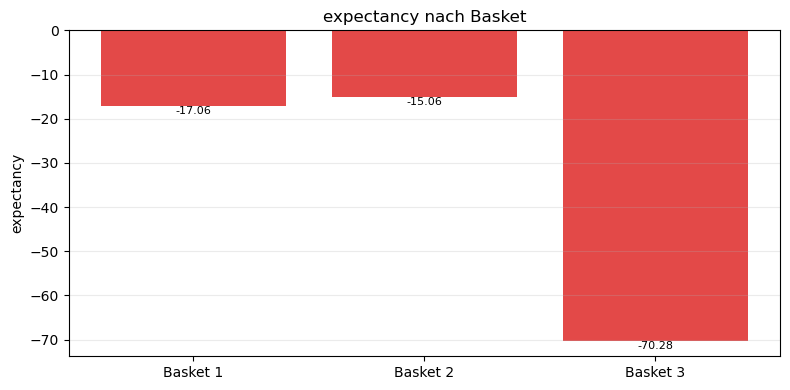

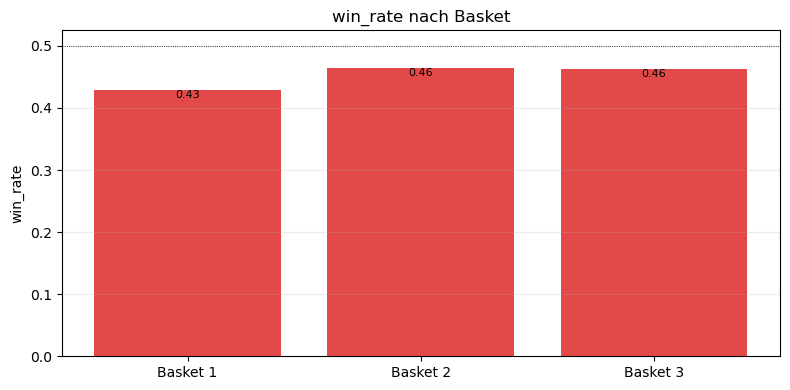

In [20]:
best_per_basket_rows = []
for (basket, candle_minutes), result in VALIDATION_RESULTS.items():
    best_per_basket_rows.append({
        "basket": basket, "candle_minutes": candle_minutes,
        "sharpe_daily": result.metrics.get("sharpe_daily", np.nan),
        "cagr_daily": result.metrics.get("cagr_daily", np.nan),
        "n_trades": result.metrics.get("n_trades", 0),
    })
best_per_basket_df = pd.DataFrame(best_per_basket_rows)
best_per_basket_best = best_per_basket_df.sort_values("sharpe_daily", ascending=False).drop_duplicates("basket").sort_values("basket")
display(best_per_basket_best)

mbb_rows = {}
for (basket, candle_minutes), result in VALIDATION_RESULTS.items():
    if basket in best_per_basket_best["basket"].values and candle_minutes == best_per_basket_best.set_index("basket").loc[basket, "candle_minutes"]:
        if not result.metrics_by_basket.empty:
            mbb_rows[basket] = result.metrics_by_basket.loc[basket]
if mbb_rows:
    mbb_combined = pd.DataFrame(mbb_rows).T
    mbb_combined.index.name = "basket"
    bt_plots.plot_basket_metric_comparison(mbb_combined, metric="expectancy")
    bt_plots.plot_basket_metric_comparison(mbb_combined, metric="win_rate", baseline=0.5)

## 13. Kerzenlängen-Vergleich (Validierung, mittleres `sharpe_daily` je Kerzenlänge über alle Baskets)

,sharpe_test_mean,sharpe_validation_mean
candle_minutes,,
5,-3.828653,-4.834316
10,-5.234768,-7.714535
15,-3.727810,-4.988243
30,-4.500401,-4.446469
60,-6.447095,-3.686077
240,-4.583159,-6.239846


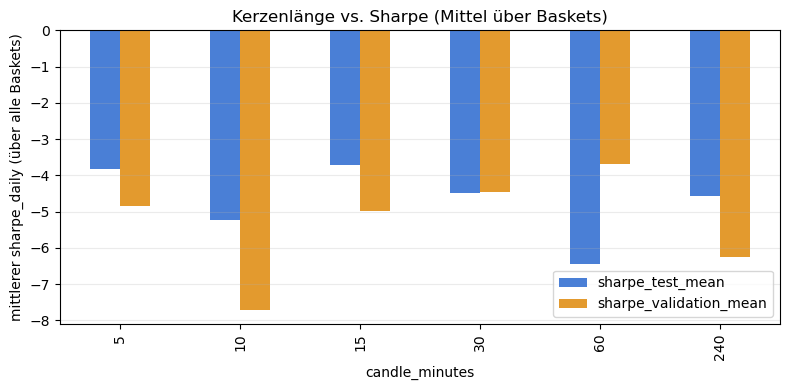

In [21]:
candle_comparison = (
    overfit_df.groupby("candle_minutes")[["sharpe_test", "sharpe_validation"]]
    .mean()
    .rename(columns={"sharpe_test": "sharpe_test_mean", "sharpe_validation": "sharpe_validation_mean"})
)
display(candle_comparison)

fig, ax = plt.subplots(figsize=(8, 4))
candle_comparison.plot(kind="bar", ax=ax, color=["#4a7fd6", "#e39a2e"])
ax.axhline(0, color="black", linewidth=0.6)
ax.set_ylabel("mittlerer sharpe_daily (über alle Baskets)")
ax.set_title("Kerzenlänge vs. Sharpe (Mittel über Baskets)")
ax.grid(True, alpha=0.25, axis="y")
plt.tight_layout()
plt.show()

## 14. Gewinner-Übersicht

In [22]:
print("Bester Basket/Kerzenlängen-Kombination je Basket (Validierung, sharpe_daily):")
display(best_per_basket_best[["basket", "candle_minutes", "sharpe_daily", "cagr_daily", "n_trades"]])

best_overall = overfit_df.sort_values("sharpe_validation", ascending=False).iloc[0]
print(f"\nGesamt-Gewinner (höchster sharpe_daily in der Validierung): "
      f"{best_overall['basket']} @ {int(best_overall['candle_minutes'])}min "
      f"(sharpe_validation={best_overall['sharpe_validation']:.3f}, sharpe_test={best_overall['sharpe_test']:.3f})")

worst_overfit = overfit_df.sort_values("sharpe_validation_minus_test").iloc[0]
print(f"Groesster Overfitting-Verdacht (sharpe faellt am staerksten von Test zu Validierung): "
      f"{worst_overfit['basket']} @ {int(worst_overfit['candle_minutes'])}min "
      f"(Δsharpe={worst_overfit['sharpe_validation_minus_test']:.3f})")

Bester Basket/Kerzenlängen-Kombination je Basket (Validierung, sharpe_daily):


,basket,candle_minutes,sharpe_daily,cagr_daily,n_trades
0,Basket 1,5,-6.671167,-0.123998,268
2,Basket 2,5,-3.818149,-0.071518,170
12,Basket 3,60,-2.890439,-0.098670,41



Gesamt-Gewinner (höchster sharpe_daily in der Validierung): Basket 3 @ 60min (sharpe_validation=-2.890, sharpe_test=-6.156)
Groesster Overfitting-Verdacht (sharpe faellt am staerksten von Test zu Validierung): Basket 1 @ 10min (Δsharpe=-5.731)


## 15. Interpretation

_Freitext: Welche Basket/Kerzenlängen-Kombination performt am besten in der Validierung
(echtes Out-of-Sample)? Fällt die Performance von Test zu Validierung stark ab (Overfitting-
Indiz, siehe Abschnitt 7)? Gibt es eine Kerzenlänge, die über alle Baskets hinweg
systematisch besser abschneidet (Abschnitt 13)? Welche Exit-Gründe dominieren in der
Validierung im Vergleich zum Test -- deutet ein Anstieg von `stop`-Exits auf ein
Regime-abhängiges Verhalten hin?_

## 16. Management Summary -- Strategie, Ergebnisse, Benchmark-Vergleich

Eigenständige Abschlusszelle: fasst Methodik/Handelsregeln (reproduzierbar), die Backtest-Kennzahlen aller Basket/Kerzenlängen-Kombinationen, die Validierungs-Equity-Kurven sowie den Benchmark-Vergleich (Buy-and-Hold BTCUSDT) auf einen Blick zusammen -- gedacht zum Abspeichern/Kopieren in die Thesis (Text + Tabelle + Plots).

`management_summary(...)` ist generisch (Titel, Kostenannahmen, Ergebnis-Dicts als Parameter)
und wird unten einmal für den Netto-Lauf und danach in Abschnitt 17 für jedes Szenario aus
`COST_SCENARIOS` aufgerufen -- vorher drei fast identische ~90-Zeilen-Zellen (Netto/kostenfrei/
fee_bps=2), jetzt eine Funktion + drei kurze Aufrufe.

MANAGEMENT SUMMARY -- Netto (mit Fees/Slippage)

--- Strategie & Methodik ---
Strategie: pairwise_zscore  |  Cliquen-Variante: raw_24h  |  Baskets: Basket 1, Basket 2, Basket 3
Tuning-Quelle (Abschnitt 2): C:\Users\ilija\Documents\OST\Semester_6\Bachlor\bachelorarbeit\data\processed\tuning_dbstore_final
Kalibrierung/Validierung-Split: 20% der neuesten Daten als Validierung (out-of-sample, nie fuer Parametersuche verwendet).
Zeitraum: 2024-07-23 -- 2026-07-22  (Test: 2024-07-23--2026-02-26, Validierung: 2026-02-27--2026-07-22)
Kostenannahmen: fee_bps=10, slippage_bps=2 (BASE_PARAMS, echte Annahmen)

Fixe Basisparameter (BASE_PARAMS, Fallback fuer Felder ohne eigenen Tuning-Wert):
  Entry-Schwelle (|Z-Score|)                    = 2.0
  Stop-Loss-Schwelle (|Z-Score|)                = 5.0
  Max. Haltedauer (Tage)                        = 4.0
  Sizing-Multiplikator-Cap                      = 4.0
  Formationsfenster (Kerzen, 5min-Basis)        = 5760
  Vol-Regime-Lookback (Kerzen, 5min-Basis

,run_id,basket,candle_minutes,best_objective,n_trials,best_params
0,basket-1-5min-standard-5db5a7ab,Basket 1,5,-0.042991,20,"{'entry_z': 0.9883533267314155, 'entry_z_delta..."
1,basket-1-10min-standard-5db5a7ab,Basket 1,10,-0.045733,20,"{'entry_z': 0.37616262889446905, 'entry_z_delt..."
2,basket-2-5min-standard-5db5a7ab,Basket 2,5,-0.037372,20,"{'entry_z': 2.388169046927335, 'entry_z_delta'..."
3,basket-2-10min-standard-5db5a7ab,Basket 2,10,-0.039099,20,"{'entry_z': 1.298141623154969, 'entry_z_delta'..."
4,basket-2-15min-standard-5db5a7ab,Basket 2,15,-0.025066,20,"{'entry_z': 1.2728931157247838, 'entry_z_delta..."
5,basket-2-30min-standard-5db5a7ab,Basket 2,30,-0.034447,20,"{'entry_z': 0.8771797252439497, 'entry_z_delta..."
6,basket-2-60min-standard-5db5a7ab,Basket 2,60,-0.043103,20,"{'entry_z': 0.37616262889446905, 'entry_z_delt..."
7,basket-2-240min-standard-5db5a7ab,Basket 2,240,-0.055431,20,"{'entry_z': 0.4116980943737963, 'entry_z_delta..."
8,basket-3-5min-standard-5db5a7ab,Basket 3,5,-0.053239,20,"{'entry_z': 2.233216666807617, 'entry_z_delta'..."
9,basket-3-10min-standard-5db5a7ab,Basket 3,10,-0.040882,20,"{'entry_z': 1.6857984397352412, 'entry_z_delta..."



--- Kennzahlen je Kombination (Validierung, out-of-sample, Netto (mit Fees/Slippage)) ---


,basket,candle_minutes,cagr_daily,ann_volatility_daily,sharpe_daily,sortino_daily,calmar_daily,max_drawdown_pct,n_trades,win_rate,profit_factor,avg_holding_hours,alpha_annualized_vs_benchmark,beta_vs_benchmark
0,Basket 1,5,-12.40%,1.98%,-6.671,-7.249,-2.420,-5.66%,268,42.91%,0.383,15.5,-12.38%,-0.000
1,Basket 1,10,-25.91%,2.39%,-12.546,-10.796,-2.307,-11.46%,452,24.34%,0.163,9.4,-25.90%,0.002
2,Basket 2,5,-7.15%,1.94%,-3.818,-4.288,-1.950,-3.89%,170,46.47%,0.589,22.3,-7.14%,0.002
3,Basket 2,10,-13.08%,2.14%,-6.529,-6.836,-2.350,-5.63%,264,45.08%,0.437,16.7,-13.07%,0.004
4,Basket 2,15,-11.43%,2.06%,-5.873,-6.539,-2.275,-5.29%,233,45.92%,0.489,18.7,-11.43%,0.004
5,Basket 2,30,-15.83%,2.89%,-5.958,-5.910,-2.382,-6.90%,253,44.66%,0.359,17.4,-15.80%,-0.000
6,Basket 2,60,-19.82%,4.90%,-4.482,-4.496,-2.356,-8.68%,311,39.23%,0.319,13.9,-19.72%,-0.000
7,Basket 2,240,-20.90%,3.23%,-7.238,-7.050,-2.350,-8.97%,222,36.49%,0.264,18.0,-20.86%,0.000
8,Basket 3,5,-8.27%,2.14%,-4.014,-3.950,-2.453,-3.48%,28,21.43%,0.182,18.3,-8.25%,0.001
9,Basket 3,10,-8.64%,2.22%,-4.069,-4.019,-2.450,-3.65%,46,36.96%,0.193,12.9,-8.62%,0.001



--- Equity-Kurven (Validierung, normiert, Netto (mit Fees/Slippage)) ---


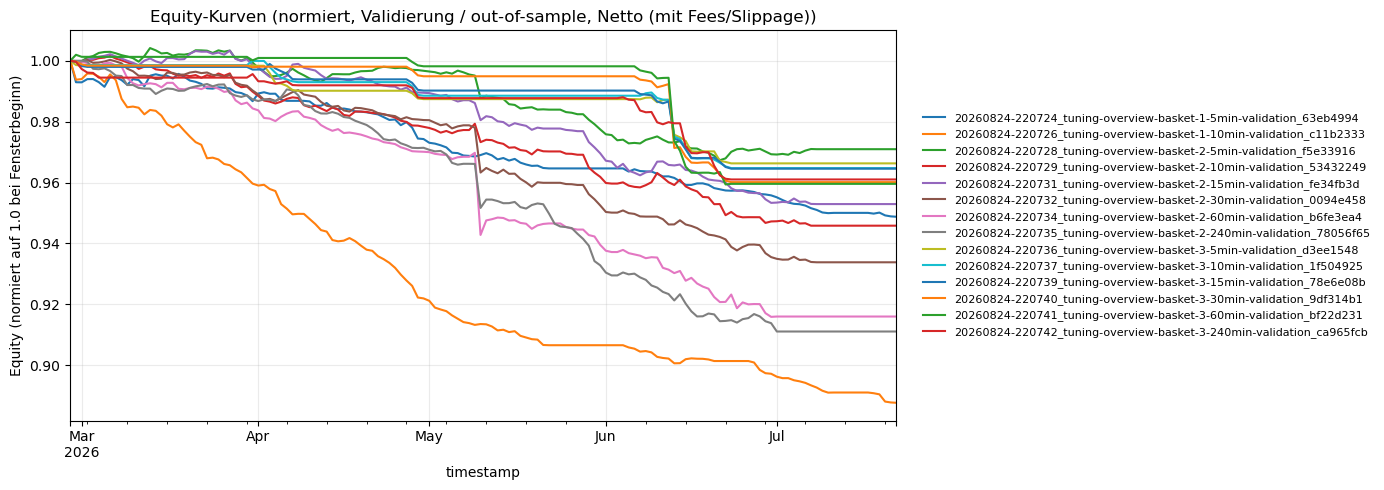

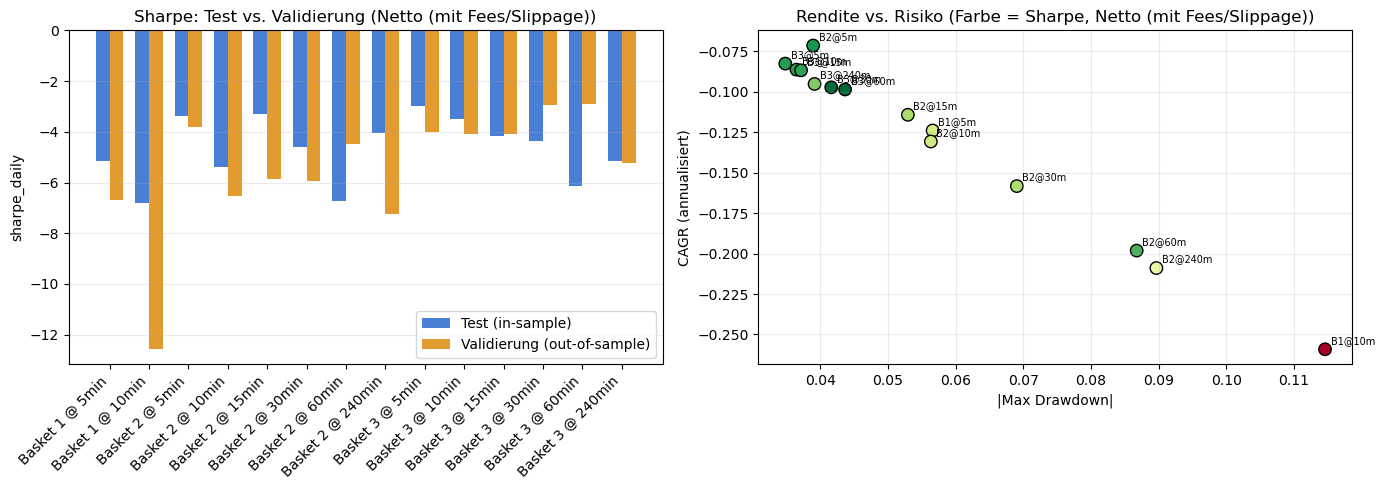


--- Benchmark-Vergleich (vs. Buy-and-Hold BTCUSDT, Netto (mit Fees/Slippage)) ---


,basket,candle_minutes,cagr_daily,sharpe_daily,alpha_annualized_vs_benchmark,beta_vs_benchmark
0,Basket 1,5,-0.123998,-6.671167,-0.123822,-0.000148
1,Basket 1,10,-0.259139,-12.545601,-0.258982,0.001728
2,Basket 2,5,-0.071518,-3.818149,-0.071449,0.002483
3,Basket 2,10,-0.130801,-6.529284,-0.130729,0.003527
4,Basket 2,15,-0.114291,-5.873088,-0.114273,0.004098
5,Basket 2,30,-0.158343,-5.957794,-0.157979,-0.000323
6,Basket 2,60,-0.198176,-4.481715,-0.197201,-0.000086
7,Basket 2,240,-0.208969,-7.238463,-0.208567,0.000414
8,Basket 3,5,-0.082685,-4.013632,-0.082500,0.000623
9,Basket 3,10,-0.086415,-4.068719,-0.086226,0.000913



--- Diskussion (automatisch generiertes Geruest -- im Fliesstext der Thesis ausformulieren) ---
Ueber alle 14 untersuchten Basket/Kerzenlaengen-Kombinationen liegt der
mittlere annualisierte Sharpe Ratio (Validierung, out-of-sample, Netto (mit Fees/Slippage)) bei -5.455. Die
beste Kombination ist Basket 3 bei 60 Minuten
Kerzenlaenge mit einem Sharpe Ratio von -2.890, einer annualisierten
Rendite von -9.87% und einem maximalen Drawdown von
-4.36% bei 41 Trades.

Der groesste Overfitting-Verdacht (staerkster Sharpe-Abfall von Test zu Validierung) zeigt sich
bei Basket 1 @ 10min
(Delta Sharpe = -5.731) -- ein deutlicher Hinweis auf Ueberanpassung an die Kalibrierungsperiode.

Gegenueber dem Buy-and-Hold-Benchmark (BTCUSDT) erzielen 0% der
Kombinationen ein positives Alpha.

[Hier im Thesis-Text weiter ausfuehren: wirtschaftliche Plausibilitaet der Ergebnisse, Vergleich mit
verwandten Arbeiten (siehe Literaturuebersicht), Grenzen des Backtests (Slippage-/Fee-Annahmen,
keine Liquiditaetsbe

In [23]:
import textwrap

_SUMMARY_METRIC_KEYS = [
    "cagr_daily", "ann_volatility_daily", "sharpe_daily", "sortino_daily", "calmar_daily",
    "max_drawdown_pct", "n_trades", "win_rate", "profit_factor", "avg_holding_hours",
    "alpha_annualized_vs_benchmark", "beta_vs_benchmark",
]
_SUMMARY_FIXED_FIELDS = [
    ("entry_z", "Entry-Schwelle (|Z-Score|)"),
    ("stop_z", "Stop-Loss-Schwelle (|Z-Score|)"),
    ("max_holding_days", "Max. Haltedauer (Tage)"),
    ("sizing_multiplier_cap", "Sizing-Multiplikator-Cap"),
    ("formation_window_candles", "Formationsfenster (Kerzen, 5min-Basis)"),
    ("vol_regime_lookback_candles", "Vol-Regime-Lookback (Kerzen, 5min-Basis)"),
    ("vol_regime_percentile_window_candles", "Vol-Regime-Perzentilfenster (Kerzen, 5min-Basis)"),
    ("min_half_life_candles", "Min. Half-Life (Kerzen)"),
    ("max_half_life_candles", "Max. Half-Life (Kerzen)"),
]


def _build_summary_metrics_df(validation_results: dict) -> pd.DataFrame:
    rows = []
    for (basket, candle_minutes), result in validation_results.items():
        row = {"basket": basket, "candle_minutes": candle_minutes}
        row.update({k: result.metrics.get(k, np.nan) for k in _SUMMARY_METRIC_KEYS})
        rows.append(row)
    return pd.DataFrame(rows).sort_values(["basket", "candle_minutes"]).reset_index(drop=True)


def management_summary(*, title: str, cost_note: str, test_results: dict, validation_results: dict,
                        validation_run_ids: list[str], reference_summary_df: pd.DataFrame | None = None,
                        reference_label: str = "Netto (Abschnitt 16, mit vollen Kosten)"):
    '''Eigenstaendiger Management-Summary-Block: Methodik, Kennzahlentabelle, Plots
    (Equity-Kurven, Sharpe Test/Validierung, Risiko-Scatter), Benchmark-Vergleich und ein
    automatisch generiertes Diskussions-Geruest. Identischer Aufbau fuer Netto-Lauf und
    jedes Kostenszenario -- reference_summary_df erlaubt einen direkten Mittelwert-Vergleich
    gegen einen bereits berechneten anderen Summary-DataFrame (z.B. Kostenszenario vs. Netto).

    Gibt das gebaute summary_metrics_df zurueck (z.B. um es spaeter als reference_summary_df
    fuer ein weiteres Szenario zu verwenden).'''
    print("=" * 90)
    print(f"MANAGEMENT SUMMARY -- {title}")
    print("=" * 90)

    print("\n--- Strategie & Methodik ---")
    print(f"Strategie: {STRATEGY_NAME}  |  Cliquen-Variante: {CLIQUE_VARIANT}  |  Baskets: {', '.join(BASKETS)}")
    print(f"Tuning-Quelle (Abschnitt 2): {TUNING_DIR_ACTIVE}")
    print(f"Kalibrierung/Validierung-Split: {int(BACKTEST_FRACTION * 100)}% der neuesten Daten "
          f"als Validierung (out-of-sample, nie fuer Parametersuche verwendet).")
    print(f"Zeitraum: {DATA_START.date()} -- {DATA_END.date()}  "
          f"(Test: {CALIBRATION_RANGE.start.date()}--{CALIBRATION_RANGE.end.date()}, "
          f"Validierung: {BACKTEST_RANGE.start.date()}--{BACKTEST_RANGE.end.date()})")
    print(f"Kostenannahmen: {cost_note}")

    print("\nFixe Basisparameter (BASE_PARAMS, Fallback fuer Felder ohne eigenen Tuning-Wert):")
    for field, label in _SUMMARY_FIXED_FIELDS:
        print(f"  {label:45s} = {getattr(BASE_PARAMS, field)}")

    print("\nPro Basket/Kerzenlaenge tatsaechlich verwendete (getunte) Parameter:")
    display(BEST_PER_BASKET_CANDLE[["run_id", "basket", "candle_minutes", "best_objective", "n_trials", "best_params"]])

    print(f"\n--- Kennzahlen je Kombination (Validierung, out-of-sample, {title}) ---")
    summary_metrics_df = _build_summary_metrics_df(validation_results)
    display(
        summary_metrics_df.style.format({
            "cagr_daily": "{:.2%}", "ann_volatility_daily": "{:.2%}", "sharpe_daily": "{:.3f}",
            "sortino_daily": "{:.3f}", "calmar_daily": "{:.3f}", "max_drawdown_pct": "{:.2%}",
            "win_rate": "{:.2%}", "profit_factor": "{:.3f}", "avg_holding_hours": "{:.1f}",
            "alpha_annualized_vs_benchmark": "{:.2%}", "beta_vs_benchmark": "{:.3f}",
        }, na_rep="--")
        .background_gradient(subset=["sharpe_daily"], cmap="RdYlGn")
    )

    print(f"\n--- Equity-Kurven (Validierung, normiert, {title}) ---")
    curves = bt_runs.compare_equity_curves(validation_run_ids)
    if not curves.empty:
        ax_curves = curves.plot(figsize=(14, 5), title=f"Equity-Kurven (normiert, Validierung / out-of-sample, {title})")
        ax_curves.set_ylabel("Equity (normiert auf 1.0 bei Fensterbeginn)")
        ax_curves.grid(True, alpha=0.25)
        ax_curves.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=8, frameon=False)
        plt.tight_layout()
        plt.show()
    else:
        print(f"Keine Equity-Kurven zum Plotten (leere Trades in allen Validierungs-Runs, {title}?).")

    scenario_overfit_df = build_overfit_df(test_results, validation_results)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    plot_overfit_bars(scenario_overfit_df, title=f"Sharpe: Test vs. Validierung ({title})", ax=axes[0])
    plot_risk_scatter(summary_metrics_df, title=f"Rendite vs. Risiko (Farbe = Sharpe, {title})", ax=axes[1])
    plt.tight_layout()
    plt.show()

    print(f"\n--- Benchmark-Vergleich (vs. Buy-and-Hold BTCUSDT, {title}) ---")
    bench_cols = ["basket", "candle_minutes", "cagr_daily", "sharpe_daily", "alpha_annualized_vs_benchmark", "beta_vs_benchmark"]
    bench_available = [c for c in bench_cols if c in summary_metrics_df.columns]
    display(summary_metrics_df[bench_available])

    print("\n--- Diskussion (automatisch generiertes Geruest -- im Fliesstext der Thesis ausformulieren) ---")
    best_row = summary_metrics_df.sort_values("sharpe_daily", ascending=False).iloc[0]
    worst_overfit_row = scenario_overfit_df.sort_values("sharpe_validation_minus_test").iloc[0]
    mean_sharpe = summary_metrics_df["sharpe_daily"].mean()
    positive_alpha_share = (summary_metrics_df["alpha_annualized_vs_benchmark"] > 0).mean() if "alpha_annualized_vs_benchmark" in summary_metrics_df else float("nan")

    reference_line = ""
    if reference_summary_df is not None:
        ref_mean_sharpe = reference_summary_df["sharpe_daily"].mean()
        ref_mean_cagr = reference_summary_df["cagr_daily"].mean()
        mean_cagr = summary_metrics_df["cagr_daily"].mean()
        reference_line = (
            f"\nIm Vergleich zum {reference_label} liegt der mittlere Sharpe Ratio hier bei "
            f"{mean_sharpe:.3f} gegenueber {ref_mean_sharpe:.3f}, die mittlere CAGR bei "
            f"{mean_cagr:.2%} gegenueber {ref_mean_cagr:.2%} -- eine CAGR-Differenz von "
            f"{(mean_cagr - ref_mean_cagr):.2%}-Punkten pro Jahr.\n"
        )

    overfit_note = ("ein deutlicher Hinweis auf Ueberanpassung an die Kalibrierungsperiode." if worst_overfit_row["sharpe_validation_minus_test"] < -0.5
                     else "im Rahmen dessen, was bei Walk-Forward-Tuning ueblich ist.")
    discussion = f'''
    Ueber alle {len(summary_metrics_df)} untersuchten Basket/Kerzenlaengen-Kombinationen liegt der
    mittlere annualisierte Sharpe Ratio (Validierung, out-of-sample, {title}) bei {mean_sharpe:.3f}. Die
    beste Kombination ist {best_row["basket"]} bei {int(best_row["candle_minutes"])} Minuten
    Kerzenlaenge mit einem Sharpe Ratio von {best_row["sharpe_daily"]:.3f}, einer annualisierten
    Rendite von {best_row["cagr_daily"]:.2%} und einem maximalen Drawdown von
    {best_row["max_drawdown_pct"]:.2%} bei {int(best_row["n_trades"])} Trades.

    Der groesste Overfitting-Verdacht (staerkster Sharpe-Abfall von Test zu Validierung) zeigt sich
    bei {worst_overfit_row["basket"]} @ {int(worst_overfit_row["candle_minutes"])}min
    (Delta Sharpe = {worst_overfit_row["sharpe_validation_minus_test"]:.3f}) -- {overfit_note}

    Gegenueber dem Buy-and-Hold-Benchmark (BTCUSDT) erzielen {positive_alpha_share:.0%} der
    Kombinationen ein positives Alpha.
    {reference_line}
    [Hier im Thesis-Text weiter ausfuehren: wirtschaftliche Plausibilitaet der Ergebnisse, Vergleich mit
    verwandten Arbeiten (siehe Literaturuebersicht), Grenzen des Backtests (Slippage-/Fee-Annahmen,
    keine Liquiditaetsbeschraenkung, Survivorship-Bias in der Symbolauswahl), und ob die Strategie unter
    realistischen Bedingungen (Transaktionskosten, Marktimpact) tragfaehig waere.]
    '''
    print(textwrap.dedent(discussion).strip())

    print("\n" + "=" * 90)
    print(f"Ende Management Summary -- {title}")
    print("=" * 90)

    return summary_metrics_df


summary_metrics_df = management_summary(
    title="Netto (mit Fees/Slippage)", cost_note="fee_bps=10, slippage_bps=2 (BASE_PARAMS, echte Annahmen)",
    test_results=TEST_RESULTS, validation_results=VALIDATION_RESULTS, validation_run_ids=VALIDATION_RUN_IDS,
)

## 17. Kostenszenarien (kostenfrei & reduzierte Gebühr) -- Vergleichsläufe + Management Summaries

Wiederholt die Kombinationen aus Abschnitt 5b (`VALIDATION_RESULTS`) für jedes Szenario aus
`COST_SCENARIOS` (Abschnitt 1) über `run_cost_scenario` -- zeigt, wie viel der Netto-Performance
durch Handelskosten/Slippage aufgezehrt wird, und wie viel eine blosse Gebührenreduktion
(statt komplett kostenfrei) davon zurückgewinnt. Alle anderen Parameter (Entry/Exit,
Formationsfenster, Vol-Regime, ...) bleiben unverändert; nur die Kostenfelder ändern sich.

Pro Szenario: Vergleichstabelle (Netto vs. Szenario), Sharpe-Balkendiagramm,
Vola-Regime-Widget (Abschnitt 11b) und vollständige Management Summary (Abschnitt 16) --
`SCENARIO_RESULTS` sammelt alle Ergebnis-Dicts für spätere Weiterverwendung
(z.B. in `02_run_comparison.ipynb`).


##########################################################################################
# KOSTENSZENARIO: kostenfrei
##########################################################################################

Basket 1 @ 5min -- kostenfrei (run_id=basket-1-5min-standard-5db5a7ab)
  Hinweis: 36 Tage Warm-up noetig (aus 10368 Kerzen) -- Test-Fenster beginnt dadurch 36 Tage nach CALIBRATION_RANGE.start.
  Aus Cache geladen (Basket-1_5min.pkl): 1131 Trades -- kein Engine-Lauf noetig.
  Test (in-sample):        861 Trades | sharpe_daily=1.597
  Validierung (out-of-sample): 268 Trades | sharpe_daily=2.616

Basket 1 @ 10min -- kostenfrei (run_id=basket-1-10min-standard-5db5a7ab)
  Hinweis: 36 Tage Warm-up noetig (aus 5184 Kerzen) -- Test-Fenster beginnt dadurch 36 Tage nach CALIBRATION_RANGE.start.
  Aus Cache geladen (Basket-1_10min.pkl): 1755 Trades -- kein Engine-Lauf noetig.
  Test (in-sample):        1301 Trades | sharpe_daily=2.149
  Validierung (out-of-sample): 452 Trades | sharpe_d

,basket,candle_minutes,cagr_netto,cagr_szenario,cagr_differenz_pp,sharpe_netto,sharpe_szenario,n_trades,cost_pct_of_gross_profit
0,Basket 1,5,-12.40%,6.31%,18.71%,-6.671,2.616,268,99.39%
1,Basket 1,10,-25.91%,4.68%,30.59%,-12.546,1.969,452,159.65%
2,Basket 2,5,-7.15%,4.29%,11.44%,-3.818,2.117,170,68.53%
3,Basket 2,10,-13.08%,4.36%,17.44%,-6.529,1.937,264,86.30%
4,Basket 2,15,-11.43%,3.33%,14.76%,-5.873,1.425,233,76.31%
5,Basket 2,30,-15.83%,-0.14%,15.69%,-5.958,-0.032,253,87.78%
6,Basket 2,60,-19.82%,0.69%,20.51%,-4.482,0.165,311,101.72%
7,Basket 2,240,-20.90%,-6.28%,14.61%,-7.238,-1.941,222,103.05%
8,Basket 3,5,-8.27%,-6.60%,1.67%,-4.014,-3.343,28,75.00%
9,Basket 3,10,-8.64%,-5.64%,3.00%,-4.069,-2.854,46,93.72%


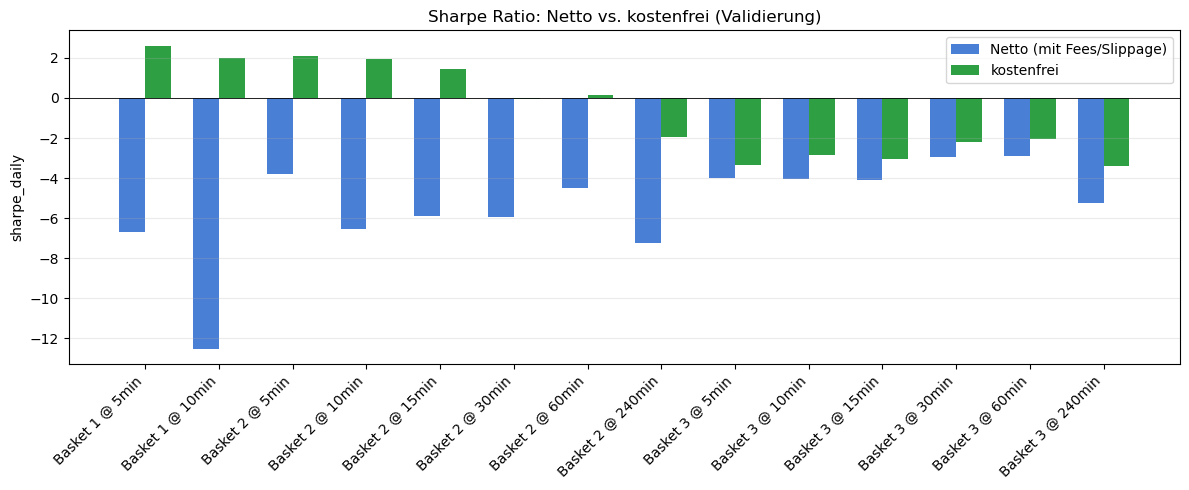


Mittlere CAGR-Differenz (kostenfrei minus netto) ueber alle Kombinationen: 11.48%-Punkte.


HTML(value='<b>Vola-Regime-Verteilung -- kostenfrei</b>')

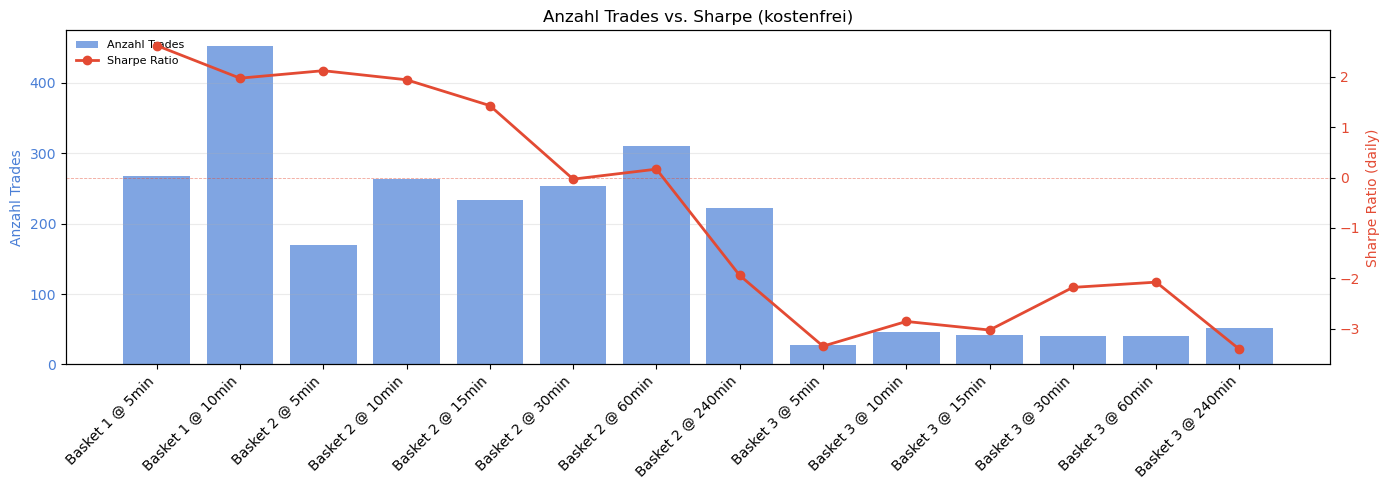

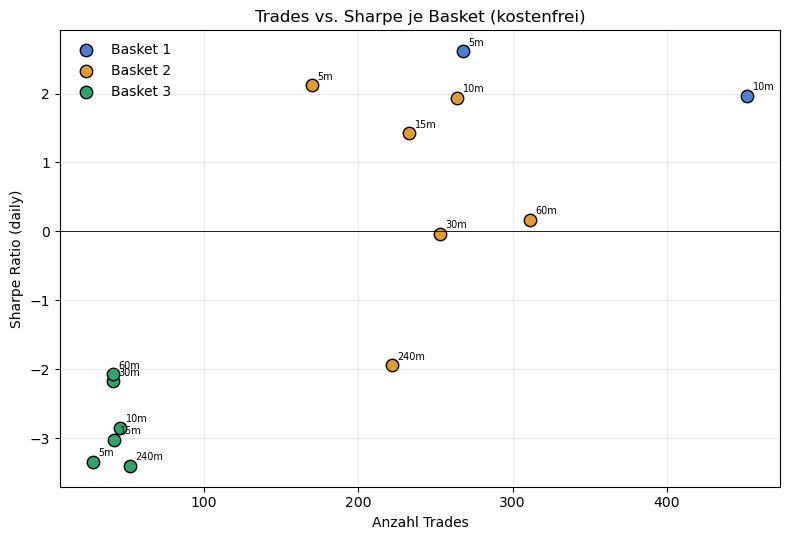

MANAGEMENT SUMMARY -- kostenfrei

--- Strategie & Methodik ---
Strategie: pairwise_zscore  |  Cliquen-Variante: raw_24h  |  Baskets: Basket 1, Basket 2, Basket 3
Tuning-Quelle (Abschnitt 2): C:\Users\ilija\Documents\OST\Semester_6\Bachlor\bachelorarbeit\data\processed\tuning_dbstore_final
Kalibrierung/Validierung-Split: 20% der neuesten Daten als Validierung (out-of-sample, nie fuer Parametersuche verwendet).
Zeitraum: 2024-07-23 -- 2026-07-22  (Test: 2024-07-23--2026-02-26, Validierung: 2026-02-27--2026-07-22)
Kostenannahmen: {'fee_bps': 0.0, 'slippage_bps': 0.0, 'slippage_high_low_factor': 0.0} (sonst identisch zum Netto-Lauf)

Fixe Basisparameter (BASE_PARAMS, Fallback fuer Felder ohne eigenen Tuning-Wert):
  Entry-Schwelle (|Z-Score|)                    = 2.0
  Stop-Loss-Schwelle (|Z-Score|)                = 5.0
  Max. Haltedauer (Tage)                        = 4.0
  Sizing-Multiplikator-Cap                      = 4.0
  Formationsfenster (Kerzen, 5min-Basis)        = 5760
  Vol-Reg

,run_id,basket,candle_minutes,best_objective,n_trials,best_params
0,basket-1-5min-standard-5db5a7ab,Basket 1,5,-0.042991,20,"{'entry_z': 0.9883533267314155, 'entry_z_delta..."
1,basket-1-10min-standard-5db5a7ab,Basket 1,10,-0.045733,20,"{'entry_z': 0.37616262889446905, 'entry_z_delt..."
2,basket-2-5min-standard-5db5a7ab,Basket 2,5,-0.037372,20,"{'entry_z': 2.388169046927335, 'entry_z_delta'..."
3,basket-2-10min-standard-5db5a7ab,Basket 2,10,-0.039099,20,"{'entry_z': 1.298141623154969, 'entry_z_delta'..."
4,basket-2-15min-standard-5db5a7ab,Basket 2,15,-0.025066,20,"{'entry_z': 1.2728931157247838, 'entry_z_delta..."
5,basket-2-30min-standard-5db5a7ab,Basket 2,30,-0.034447,20,"{'entry_z': 0.8771797252439497, 'entry_z_delta..."
6,basket-2-60min-standard-5db5a7ab,Basket 2,60,-0.043103,20,"{'entry_z': 0.37616262889446905, 'entry_z_delt..."
7,basket-2-240min-standard-5db5a7ab,Basket 2,240,-0.055431,20,"{'entry_z': 0.4116980943737963, 'entry_z_delta..."
8,basket-3-5min-standard-5db5a7ab,Basket 3,5,-0.053239,20,"{'entry_z': 2.233216666807617, 'entry_z_delta'..."
9,basket-3-10min-standard-5db5a7ab,Basket 3,10,-0.040882,20,"{'entry_z': 1.6857984397352412, 'entry_z_delta..."



--- Kennzahlen je Kombination (Validierung, out-of-sample, kostenfrei) ---


,basket,candle_minutes,cagr_daily,ann_volatility_daily,sharpe_daily,sortino_daily,calmar_daily,max_drawdown_pct,n_trades,win_rate,profit_factor,avg_holding_hours,alpha_annualized_vs_benchmark,beta_vs_benchmark
0,Basket 1,5,6.31%,2.35%,2.616,4.839,6.014,-1.20%,268,65.67%,1.352,15.5,6.35%,-0.003
1,Basket 1,10,4.68%,2.33%,1.969,3.507,4.222,-1.19%,452,70.13%,1.250,9.4,4.71%,-0.002
2,Basket 2,5,4.29%,1.99%,2.117,3.077,2.545,-1.85%,170,61.18%,1.314,22.3,4.30%,0.001
3,Basket 2,10,4.36%,2.21%,1.937,2.867,4.353,-1.12%,264,65.15%,1.235,16.7,4.36%,0.005
4,Basket 2,15,3.33%,2.32%,1.425,2.196,1.969,-1.82%,233,62.66%,1.178,18.7,3.33%,0.005
5,Basket 2,30,-0.14%,3.00%,-0.032,-0.038,-0.056,-2.68%,253,65.22%,0.971,17.4,-0.10%,0.001
6,Basket 2,60,0.69%,4.86%,0.165,0.181,0.258,-3.29%,311,63.99%,1.025,13.9,0.79%,0.003
7,Basket 2,240,-6.28%,3.31%,-1.941,-2.181,-1.487,-4.32%,222,57.21%,0.720,18.0,-6.23%,-0.001
8,Basket 3,5,-6.60%,2.04%,-3.343,-3.338,-2.466,-2.81%,28,28.57%,0.262,18.3,-6.59%,0.002
9,Basket 3,10,-5.64%,2.03%,-2.854,-2.899,-2.326,-2.72%,46,47.83%,0.374,12.9,-5.63%,0.002



--- Equity-Kurven (Validierung, normiert, kostenfrei) ---


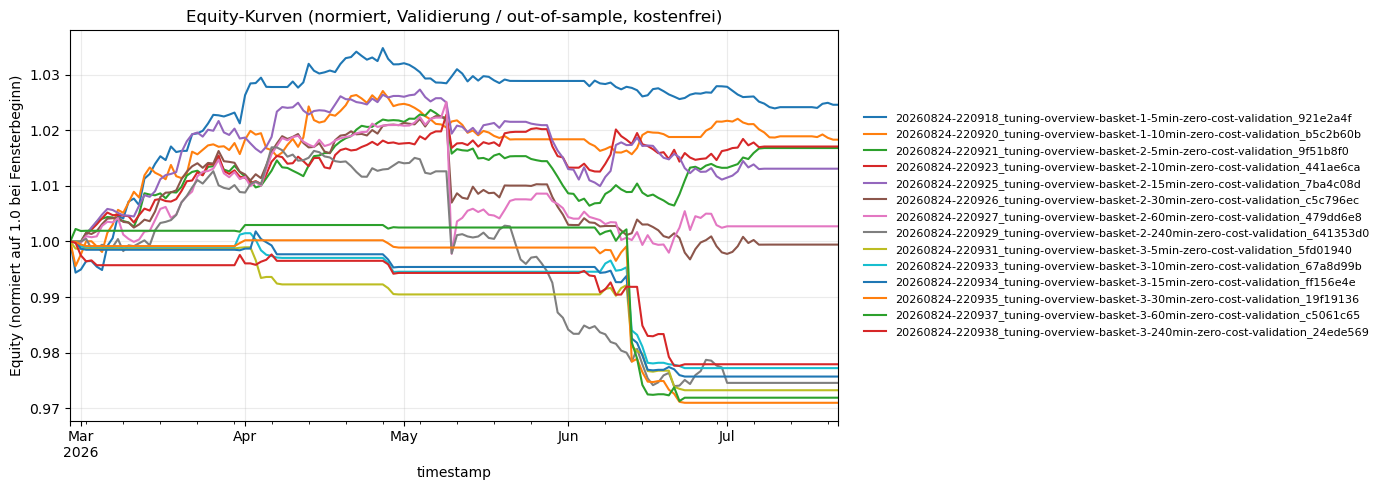

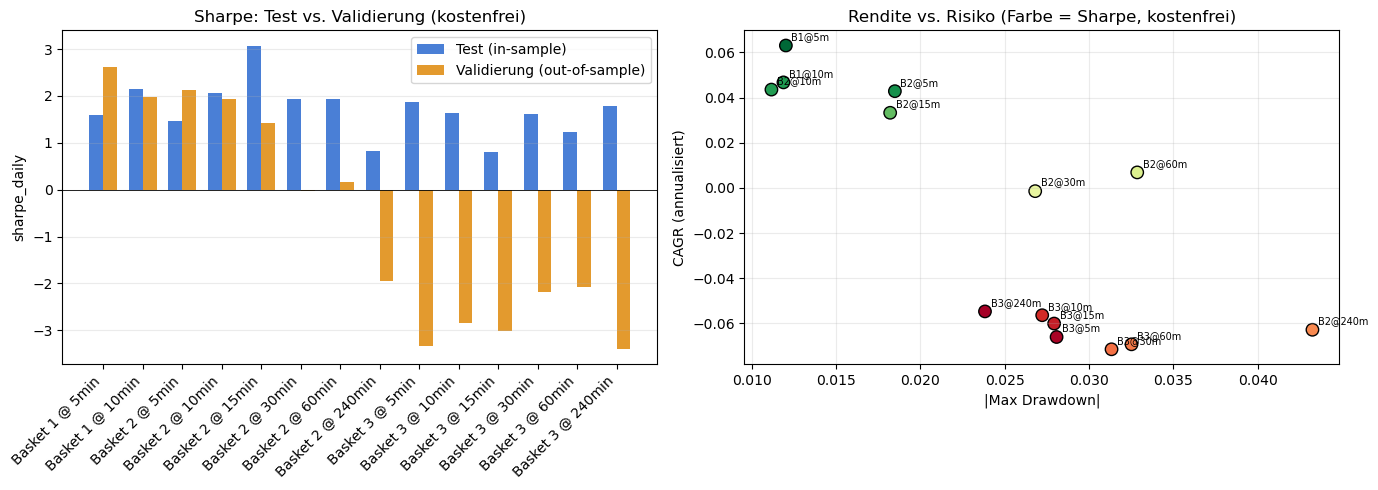


--- Benchmark-Vergleich (vs. Buy-and-Hold BTCUSDT, kostenfrei) ---


,basket,candle_minutes,cagr_daily,sharpe_daily,alpha_annualized_vs_benchmark,beta_vs_benchmark
0,Basket 1,5,0.063087,2.616015,0.063533,-0.003211
1,Basket 1,10,0.046756,1.968812,0.047133,-0.002177
2,Basket 2,5,0.042864,2.117339,0.043006,0.001345
3,Basket 2,10,0.043566,1.936957,0.043604,0.005009
4,Basket 2,15,0.033292,1.425451,0.033343,0.004660
5,Basket 2,30,-0.001422,-0.032382,-0.001008,0.000705
6,Basket 2,60,0.006880,0.165469,0.007936,0.002651
7,Basket 2,240,-0.062832,-1.941105,-0.062288,-0.000958
8,Basket 3,5,-0.066035,-3.343253,-0.065911,0.001642
9,Basket 3,10,-0.056390,-2.853539,-0.056272,0.001933



--- Diskussion (automatisch generiertes Geruest -- im Fliesstext der Thesis ausformulieren) ---
Ueber alle 14 untersuchten Basket/Kerzenlaengen-Kombinationen liegt der
    mittlere annualisierte Sharpe Ratio (Validierung, out-of-sample, kostenfrei) bei -0.616. Die
    beste Kombination ist Basket 1 bei 5 Minuten
    Kerzenlaenge mit einem Sharpe Ratio von 2.616, einer annualisierten
    Rendite von 6.31% und einem maximalen Drawdown von
    -1.20% bei 268 Trades.

    Der groesste Overfitting-Verdacht (staerkster Sharpe-Abfall von Test zu Validierung) zeigt sich
    bei Basket 3 @ 5min
    (Delta Sharpe = -5.219) -- ein deutlicher Hinweis auf Ueberanpassung an die Kalibrierungsperiode.

    Gegenueber dem Buy-and-Hold-Benchmark (BTCUSDT) erzielen 43% der
    Kombinationen ein positives Alpha.

Im Vergleich zum Netto-Lauf (Abschnitt 16, mit vollen Kosten) liegt der mittlere Sharpe Ratio hier bei -0.616 gegenueber -5.455, die mittlere CAGR bei -1.47% gegenueber -12.95% -- eine CAGR-Diff

,basket,candle_minutes,cagr_netto,cagr_szenario,cagr_differenz_pp,sharpe_netto,sharpe_szenario,n_trades,cost_pct_of_gross_profit
0,Basket 1,5,-12.40%,2.93%,15.33%,-6.671,1.307,268,99.39%
1,Basket 1,10,-25.91%,-1.18%,24.73%,-12.546,-0.542,452,159.65%
2,Basket 2,5,-7.15%,2.29%,9.44%,-3.818,1.158,170,68.53%
3,Basket 2,10,-13.08%,1.23%,14.31%,-6.529,0.570,264,86.30%
4,Basket 2,15,-11.43%,0.71%,12.14%,-5.873,0.324,233,76.31%
5,Basket 2,30,-15.83%,-2.95%,12.89%,-5.958,-0.992,253,87.78%
6,Basket 2,60,-19.82%,-3.06%,16.76%,-4.482,-0.617,311,101.72%
7,Basket 2,240,-20.90%,-8.89%,12.00%,-7.238,-2.817,222,103.05%
8,Basket 3,5,-8.27%,-6.88%,1.39%,-4.014,-3.463,28,75.00%
9,Basket 3,10,-8.64%,-6.15%,2.50%,-4.069,-3.080,46,93.72%


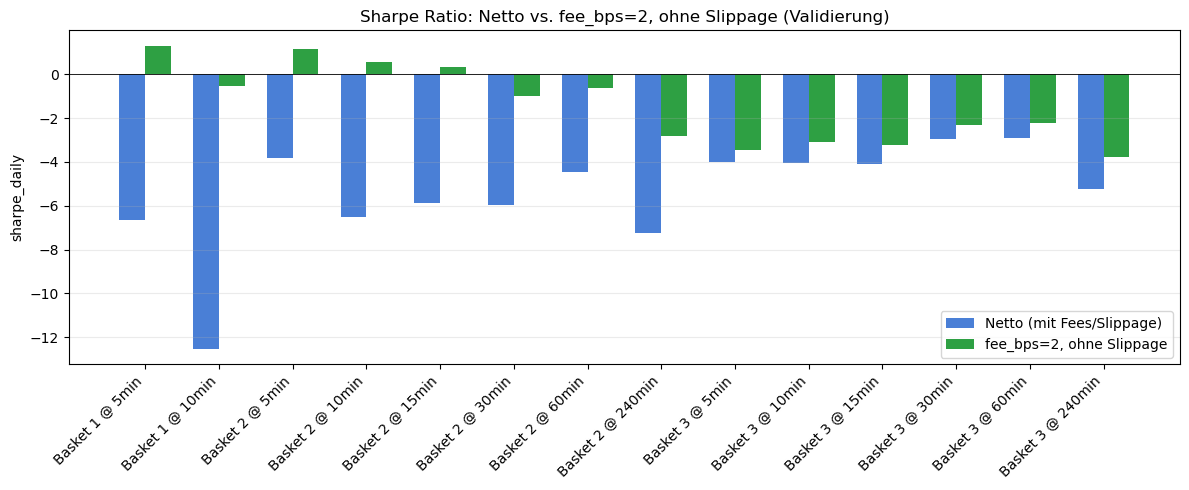


Mittlere CAGR-Differenz (fee_bps=2, ohne Slippage minus netto) ueber alle Kombinationen: 9.40%-Punkte.


HTML(value='<b>Vola-Regime-Verteilung -- fee_bps=2, ohne Slippage</b>')

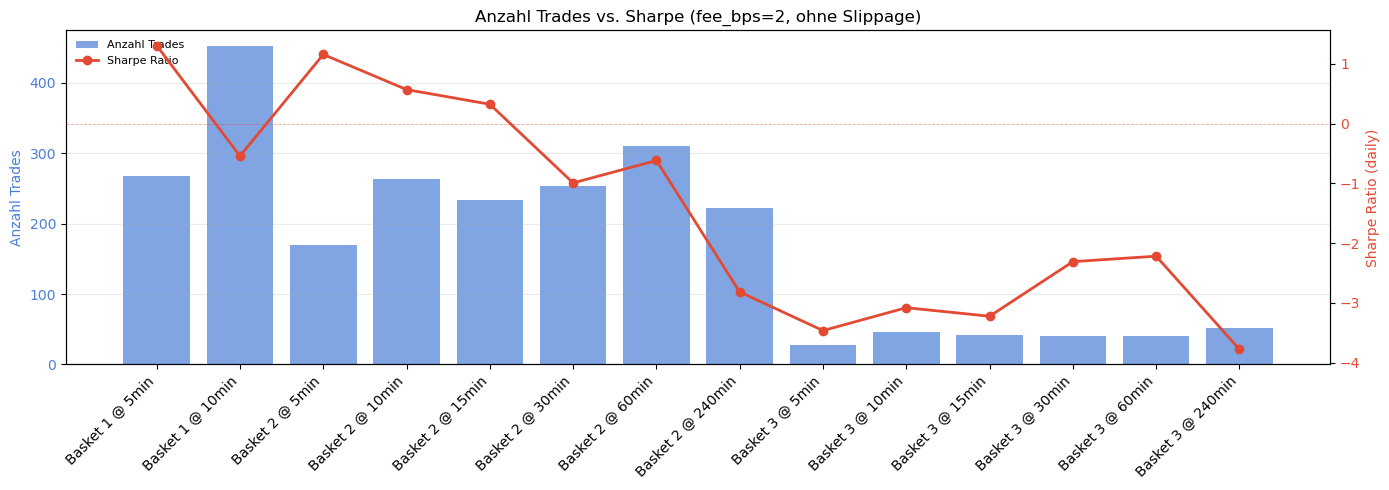

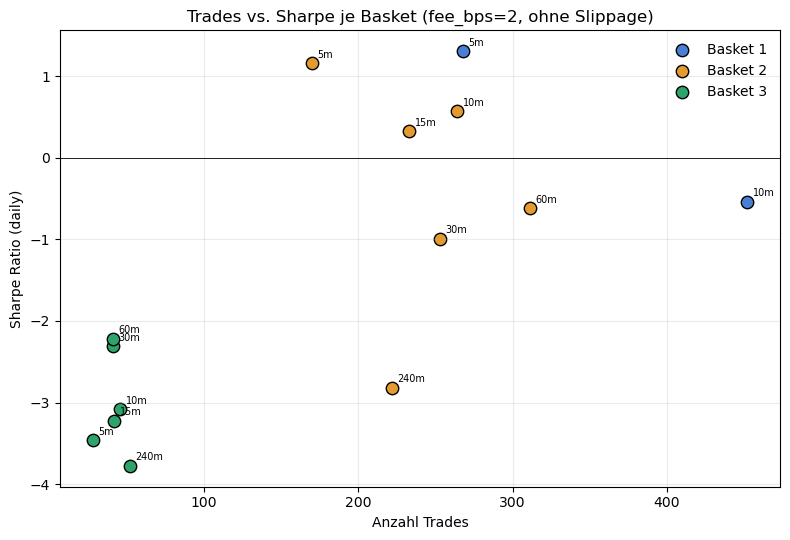

MANAGEMENT SUMMARY -- fee_bps=2, ohne Slippage

--- Strategie & Methodik ---
Strategie: pairwise_zscore  |  Cliquen-Variante: raw_24h  |  Baskets: Basket 1, Basket 2, Basket 3
Tuning-Quelle (Abschnitt 2): C:\Users\ilija\Documents\OST\Semester_6\Bachlor\bachelorarbeit\data\processed\tuning_dbstore_final
Kalibrierung/Validierung-Split: 20% der neuesten Daten als Validierung (out-of-sample, nie fuer Parametersuche verwendet).
Zeitraum: 2024-07-23 -- 2026-07-22  (Test: 2024-07-23--2026-02-26, Validierung: 2026-02-27--2026-07-22)
Kostenannahmen: {'fee_bps': 2.0, 'slippage_bps': 0.0, 'slippage_high_low_factor': 0.0} (sonst identisch zum Netto-Lauf)

Fixe Basisparameter (BASE_PARAMS, Fallback fuer Felder ohne eigenen Tuning-Wert):
  Entry-Schwelle (|Z-Score|)                    = 2.0
  Stop-Loss-Schwelle (|Z-Score|)                = 5.0
  Max. Haltedauer (Tage)                        = 4.0
  Sizing-Multiplikator-Cap                      = 4.0
  Formationsfenster (Kerzen, 5min-Basis)        = 

,run_id,basket,candle_minutes,best_objective,n_trials,best_params
0,basket-1-5min-standard-5db5a7ab,Basket 1,5,-0.042991,20,"{'entry_z': 0.9883533267314155, 'entry_z_delta..."
1,basket-1-10min-standard-5db5a7ab,Basket 1,10,-0.045733,20,"{'entry_z': 0.37616262889446905, 'entry_z_delt..."
2,basket-2-5min-standard-5db5a7ab,Basket 2,5,-0.037372,20,"{'entry_z': 2.388169046927335, 'entry_z_delta'..."
3,basket-2-10min-standard-5db5a7ab,Basket 2,10,-0.039099,20,"{'entry_z': 1.298141623154969, 'entry_z_delta'..."
4,basket-2-15min-standard-5db5a7ab,Basket 2,15,-0.025066,20,"{'entry_z': 1.2728931157247838, 'entry_z_delta..."
5,basket-2-30min-standard-5db5a7ab,Basket 2,30,-0.034447,20,"{'entry_z': 0.8771797252439497, 'entry_z_delta..."
6,basket-2-60min-standard-5db5a7ab,Basket 2,60,-0.043103,20,"{'entry_z': 0.37616262889446905, 'entry_z_delt..."
7,basket-2-240min-standard-5db5a7ab,Basket 2,240,-0.055431,20,"{'entry_z': 0.4116980943737963, 'entry_z_delta..."
8,basket-3-5min-standard-5db5a7ab,Basket 3,5,-0.053239,20,"{'entry_z': 2.233216666807617, 'entry_z_delta'..."
9,basket-3-10min-standard-5db5a7ab,Basket 3,10,-0.040882,20,"{'entry_z': 1.6857984397352412, 'entry_z_delta..."



--- Kennzahlen je Kombination (Validierung, out-of-sample, fee_bps=2, ohne Slippage) ---


,basket,candle_minutes,cagr_daily,ann_volatility_daily,sharpe_daily,sortino_daily,calmar_daily,max_drawdown_pct,n_trades,win_rate,profit_factor,avg_holding_hours,alpha_annualized_vs_benchmark,beta_vs_benchmark
0,Basket 1,5,2.93%,2.23%,1.307,2.183,2.118,-1.48%,268,62.69%,1.120,15.5,2.97%,-0.003
1,Basket 1,10,-1.18%,2.15%,-0.542,-0.807,-0.769,-1.59%,452,65.27%,0.925,9.4,-1.15%,-0.002
2,Basket 2,5,2.29%,1.97%,1.158,1.604,1.207,-2.04%,170,58.82%,1.156,22.3,2.30%,0.002
3,Basket 2,10,1.23%,2.18%,0.570,0.791,1.001,-1.37%,264,63.64%,1.055,16.7,1.23%,0.005
4,Basket 2,15,0.71%,2.26%,0.324,0.472,0.370,-2.16%,233,60.52%,1.027,18.7,0.71%,0.005
5,Basket 2,30,-2.95%,2.97%,-0.992,-1.120,-1.051,-2.96%,253,62.85%,0.838,17.4,-2.91%,0.001
6,Basket 2,60,-3.06%,4.85%,-0.617,-0.663,-1.012,-3.29%,311,61.09%,0.861,13.9,-2.96%,0.002
7,Basket 2,240,-8.89%,3.29%,-2.817,-3.088,-1.844,-4.92%,222,54.50%,0.618,18.0,-8.84%,-0.001
8,Basket 3,5,-6.88%,2.05%,-3.463,-3.447,-2.464,-2.92%,28,28.57%,0.247,18.3,-6.87%,0.001
9,Basket 3,10,-6.15%,2.05%,-3.080,-3.112,-2.357,-2.85%,46,47.83%,0.335,12.9,-6.13%,0.002



--- Equity-Kurven (Validierung, normiert, fee_bps=2, ohne Slippage) ---


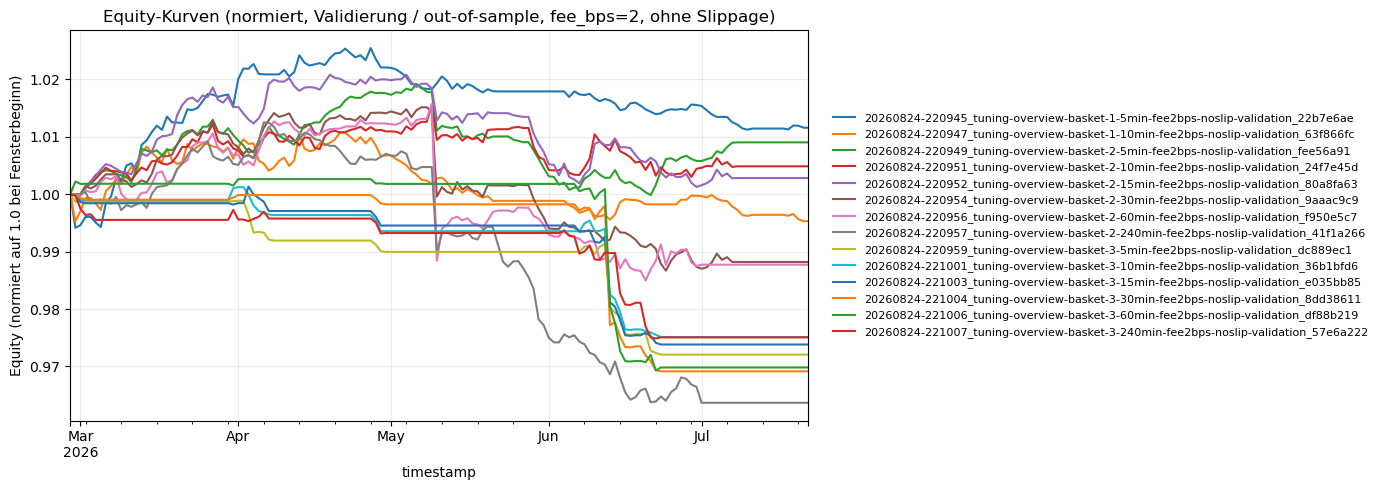

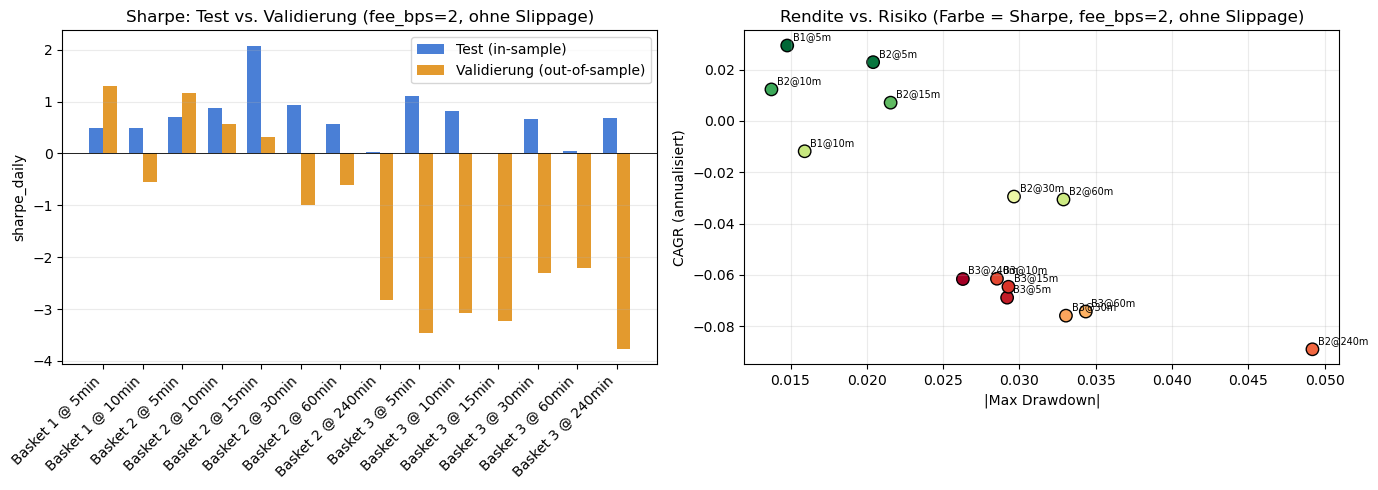


--- Benchmark-Vergleich (vs. Buy-and-Hold BTCUSDT, fee_bps=2, ohne Slippage) ---


,basket,candle_minutes,cagr_daily,sharpe_daily,alpha_annualized_vs_benchmark,beta_vs_benchmark
0,Basket 1,5,0.029346,1.306920,0.029727,-0.002700
1,Basket 1,10,-0.011826,-0.542078,-0.011536,-0.001523
2,Basket 2,5,0.022869,1.157595,0.022995,0.001535
3,Basket 2,10,0.012254,0.569830,0.012292,0.004762
4,Basket 2,15,0.007094,0.324106,0.007134,0.004567
5,Basket 2,30,-0.029468,-0.992286,-0.029066,0.000533
6,Basket 2,60,-0.030610,-0.616972,-0.029576,0.002195
7,Basket 2,240,-0.088934,-2.816645,-0.088420,-0.000730
8,Basket 3,5,-0.068830,-3.463393,-0.068696,0.001472
9,Basket 3,10,-0.061461,-3.080393,-0.061332,0.001763



--- Diskussion (automatisch generiertes Geruest -- im Fliesstext der Thesis ausformulieren) ---
Ueber alle 14 untersuchten Basket/Kerzenlaengen-Kombinationen liegt der
    mittlere annualisierte Sharpe Ratio (Validierung, out-of-sample, fee_bps=2, ohne Slippage) bei -1.406. Die
    beste Kombination ist Basket 1 bei 5 Minuten
    Kerzenlaenge mit einem Sharpe Ratio von 1.307, einer annualisierten
    Rendite von 2.93% und einem maximalen Drawdown von
    -1.48% bei 268 Trades.

    Der groesste Overfitting-Verdacht (staerkster Sharpe-Abfall von Test zu Validierung) zeigt sich
    bei Basket 3 @ 5min
    (Delta Sharpe = -4.568) -- ein deutlicher Hinweis auf Ueberanpassung an die Kalibrierungsperiode.

    Gegenueber dem Buy-and-Hold-Benchmark (BTCUSDT) erzielen 29% der
    Kombinationen ein positives Alpha.

Im Vergleich zum Netto-Lauf (Abschnitt 16, mit vollen Kosten) liegt der mittlere Sharpe Ratio hier bei -1.406 gegenueber -5.455, die mittlere CAGR bei -3.54% gegenueber -12.95% -- 

In [24]:
SCENARIO_RESULTS: dict[str, dict] = {}

for scenario_title, cost_overrides, cache_suffix in COST_SCENARIOS:
    print(f"\n{'#' * 90}\n# KOSTENSZENARIO: {scenario_title}\n{'#' * 90}")

    full_r, test_r, val_r, test_ids, val_ids, _skip = run_cost_scenario(
        cost_overrides=cost_overrides, cache_suffix=cache_suffix, label_suffix=scenario_title,
        allowed_keys=set(VALIDATION_RESULTS.keys()),
    )
    SCENARIO_RESULTS[scenario_title] = {
        "full": full_r, "test": test_r, "validation": val_r,
        "test_run_ids": test_ids, "validation_run_ids": val_ids,
    }

    # --- Vergleichsuebersicht: Netto vs. Szenario, je Kombination -----------------
    print("\n" + "=" * 90)
    print(f"VERGLEICH: NETTO (mit Fees/Slippage) vs. {scenario_title} (Validierung, out-of-sample)")
    print("=" * 90)
    compare_rows = []
    for key, scen_result in val_r.items():
        basket, candle_minutes = key
        net_result = VALIDATION_RESULTS[key]
        net_cagr, scen_cagr = net_result.metrics.get("cagr_daily", np.nan), scen_result.metrics.get("cagr_daily", np.nan)
        net_sharpe, scen_sharpe = net_result.metrics.get("sharpe_daily", np.nan), scen_result.metrics.get("sharpe_daily", np.nan)
        compare_rows.append({
            "basket": basket, "candle_minutes": candle_minutes,
            "cagr_netto": net_cagr, "cagr_szenario": scen_cagr,
            "cagr_differenz_pp": (scen_cagr - net_cagr) if pd.notna(net_cagr) and pd.notna(scen_cagr) else np.nan,
            "sharpe_netto": net_sharpe, "sharpe_szenario": scen_sharpe,
            "n_trades": net_result.metrics.get("n_trades", 0),
            "cost_pct_of_gross_profit": net_result.metrics.get("cost_pct_of_gross_profit", np.nan),
        })
    cost_compare_df = pd.DataFrame(compare_rows).sort_values(["basket", "candle_minutes"]).reset_index(drop=True)
    display(
        cost_compare_df.style.format({
            "cagr_netto": "{:.2%}", "cagr_szenario": "{:.2%}", "cagr_differenz_pp": "{:.2%}",
            "sharpe_netto": "{:.3f}", "sharpe_szenario": "{:.3f}", "cost_pct_of_gross_profit": "{:.2%}",
        }, na_rep="--")
        .background_gradient(subset=["cagr_differenz_pp"], cmap="Reds")
    )

    fig, ax = plt.subplots(figsize=(12, 5))
    labels = cost_compare_df["basket"].astype(str) + " @ " + cost_compare_df["candle_minutes"].astype(str) + "min"
    x = np.arange(len(cost_compare_df))
    width = 0.35
    ax.bar(x - width / 2, cost_compare_df["sharpe_netto"], width, label="Netto (mit Fees/Slippage)", color="#4a7fd6")
    ax.bar(x + width / 2, cost_compare_df["sharpe_szenario"], width, label=scenario_title, color="#2ea043")
    ax.axhline(0, color="black", linewidth=0.6)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=45, ha="right")
    ax.set_ylabel("sharpe_daily")
    ax.set_title(f"Sharpe Ratio: Netto vs. {scenario_title} (Validierung)")
    ax.legend()
    ax.grid(True, alpha=0.25, axis="y")
    plt.tight_layout()
    plt.show()

    mean_drag = cost_compare_df["cagr_differenz_pp"].mean()
    print(f"\nMittlere CAGR-Differenz ({scenario_title} minus netto) ueber alle Kombinationen: {mean_drag:.2%}-Punkte.")

    make_regime_widget(val_r, title=f"Vola-Regime-Verteilung -- {scenario_title}", title_suffix=f", {scenario_title}")
    plot_trades_vs_sharpe(val_r, title_suffix=f" ({scenario_title})")

    management_summary(
        title=scenario_title, cost_note=f"{cost_overrides} (sonst identisch zum Netto-Lauf)",
        test_results=test_r, validation_results=val_r, validation_run_ids=val_ids,
        reference_summary_df=summary_metrics_df, reference_label="Netto-Lauf (Abschnitt 16, mit vollen Kosten)",
    )